# Rapport de match : AC Milan 3 Liverpool 3
## Finale de la Ligue des champions 2005, Istanbul (Liverpool vainqueur aux tirs au but)

Auteur : Theo Grasso, Data Analyst Football

### Objectif

Expliquer avec les données d'événements comment Milan mène 3 à 0 à la mi-temps, puis comment Liverpool revient à 3 à 3 en six minutes. Le rapport suit quatre parties :
1. Comment Milan domine la première mi-temps.
2. Pourquoi Liverpool craque.
3. Pourquoi Milan craque en deuxième mi-temps.
4. Comment Liverpool revient.

### Données et méthode

Source : données gratuites StatsBomb (open data), soit 4 648 actions du match (passes, conduites de balle, pressings, tirs...), chacune avec la minute, le joueur et la position sur le terrain. Le terrain StatsBomb mesure 120 de long sur 80 de large, et chaque équipe attaque toujours de gauche à droite dans les données.

### Limites

Les données d'événements ne donnent pas la position des joueurs sans ballon : les positions présentées sont des moyennes sur une mi-temps, pas des photos d'un instant précis. Le mental ne se mesure pas directement : on parle de comportements observés. Les prolongations et la séance de tirs au but ne sont pas analysées.

## Préparation

Installation de la bibliothèque mplsoccer (dessin de terrains de foot), à faire une seule fois.

In [1]:
%pip install mplsoccer

In [2]:
import requests                  # sert à télécharger des fichiers depuis internet
import pandas as pd              # sert à ranger les données dans un tableau (DataFrame)
import matplotlib.pyplot as plt  # sert à dessiner des graphiques
from mplsoccer import Pitch      # sert à dessiner un terrain de foot aux dimensions StatsBomb
import matplotlib.patheffects as pe  # sert à entourer le texte d'un contour noir pour qu'il reste lisible sur les ronds


### Téléchargement des événements du match

Le match porte le numéro 2302764 dans les données StatsBomb.

In [3]:
ID_MATCH = 2302764  # numéro du match Milan Liverpool 2005 dans les données StatsBomb
# Adresse du fichier qui contient toutes les actions du match (hébergé gratuitement sur GitHub)
url = f"https://raw.githubusercontent.com/statsbomb/open-data/master/data/events/{ID_MATCH}.json"
evenements = requests.get(url, timeout=60).json()  # on télécharge le fichier et on le transforme en liste Python
# json_normalize "aplatit" les infos imbriquées : par exemple type -> name devient la colonne type_name
df = pd.json_normalize(evenements, sep="_")
print(df.shape)  # nombre de lignes (actions) et de colonnes (informations sur chaque action)

(4648, 123)


### Noms courts des joueurs

Les noms StatsBomb sont les noms complets (Ricardo Izecson dos Santos Leite pour Kaká). On les remplace par les noms connus pour des graphiques lisibles.

In [4]:
noms_courts = {
    # AC Milan
    "Nelson de Jesus da Silva": "Dida", "Marcos Evangelista de Moraes": "Cafu",
    "Jaap Stam": "Stam", "Alessandro Nesta": "Nesta", "Paolo Maldini": "Maldini",
    "Andrea Pirlo": "Pirlo", "Ivan Gennaro Gattuso": "Gattuso", "Clarence Seedorf": "Seedorf",
    "Ricardo Izecson dos Santos Leite": "Kaká", "Andriy Shevchenko": "Shevchenko",
    "Hernán Jorge Crespo": "Crespo", "Jon Dahl Tomasson": "Tomasson",
    "Claudio Santos": "Serginho", "Rui Manuel César Costa": "Rui Costa",
    # Liverpool
    "Jerzy Dudek": "Dudek", "Steve Finnan": "Finnan", "Jamie Carragher": "Carragher",
    "Sami Hyypiä": "Hyypiä", "Djimi Traoré": "Traoré", "Xabier Alonso Olano": "Alonso",
    "Luis Javier García Sanz": "García", "Steven Gerrard": "Gerrard",
    "John Arne Semundseth Riise": "Riise", "Harry Kewell": "Kewell", "Milan Baroš": "Baroš",
    "Vladimir Smicer": "Šmicer", "Dietmar Hamann": "Hamann", "Djibril Cissé": "Cissé",
}
KAKA = "Ricardo Izecson dos Santos Leite"  # nom complet de Kaká, utilisé plusieurs fois

### Compositions de départ

Les deux premières lignes du fichier contiennent le système de jeu et les onze titulaires de chaque équipe.

In [5]:
for i in [0, 1]:  # ligne 0 = première équipe, ligne 1 = deuxième équipe
    equipe = evenements[i]["team"]["name"]                 # nom de l'équipe
    systeme = evenements[i]["tactics"]["formation"]        # système de jeu, par exemple 41212
    print(equipe, ": système", systeme)                    # on affiche l'équipe et son système
    for joueur in evenements[i]["tactics"]["lineup"]:      # on passe en revue les onze titulaires
        nom = noms_courts[joueur["player"]["name"]]        # nom court du joueur
        print("  ", joueur["jersey_number"], nom, ":", joueur["position"]["name"])  # numéro, nom, poste
    print()                                                # ligne vide pour séparer les deux équipes

AC Milan : système 41212
   1 Dida : Goalkeeper
   2 Cafu : Right Back
   31 Stam : Right Center Back
   13 Nesta : Left Center Back
   3 Maldini : Left Back
   21 Pirlo : Center Defensive Midfield
   8 Gattuso : Right Center Midfield
   20 Seedorf : Left Center Midfield
   22 Kaká : Center Attacking Midfield
   7 Shevchenko : Right Center Forward
   11 Crespo : Left Center Forward

Liverpool : système 4411
   1 Dudek : Goalkeeper
   3 Finnan : Right Back
   23 Carragher : Right Center Back
   4 Hyypiä : Left Center Back
   21 Traoré : Left Back
   14 Alonso : Left Defensive Midfield
   10 García : Right Midfield
   8 Gerrard : Right Center Midfield
   6 Riise : Left Midfield
   7 Kewell : Center Attacking Midfield
   5 Baroš : Center Forward



### Chronologie : buts et remplacements

Périodes : 1 et 2 pour les mi-temps, 3 et 4 pour les prolongations, 5 pour les tirs au but (retirés de l'analyse).

In [6]:
jeu = df[df["period"] <= 4]  # on enlève la séance de tirs au but (période 5)

buts = jeu[(jeu["type_name"] == "Shot") & (jeu["shot_outcome_name"] == "Goal")].copy()  # tirs qui ont fini au fond
buts["buteur"] = buts["player_name"].map(noms_courts)                                   # nom court du buteur
print("BUTS")                                                                           # titre
print(buts[["minute", "team_name", "buteur"]].to_string(index=False))                   # minute, équipe, buteur

changements = jeu[jeu["type_name"] == "Substitution"].copy()                             # remplacements
changements["sort"] = changements["player_name"].map(noms_courts)                        # joueur qui sort
changements["entre"] = changements["substitution_replacement_name"].map(noms_courts)     # joueur qui entre
print("\nREMPLACEMENTS")                                                                # titre (\n = saut de ligne)
print(changements[["minute", "team_name", "sort", "entre"]].to_string(index=False))      # le détail

BUTS
 minute team_name  buteur
      0  AC Milan Maldini
     38  AC Milan  Crespo
     42  AC Milan  Crespo
     53 Liverpool Gerrard
     55 Liverpool  Šmicer
     59 Liverpool  Alonso

REMPLACEMENTS
 minute team_name    sort     entre
     22 Liverpool  Kewell    Šmicer
     45 Liverpool  Finnan    Hamann
     84 Liverpool   Baroš     Cissé
     84  AC Milan  Crespo  Tomasson
     85  AC Milan Seedorf  Serginho
    111  AC Milan Gattuso Rui Costa


### Vue d'ensemble période par période

Passes, pressings, tirs et xG de chaque équipe. Le pressing est aussi ramené à 100 passes adverses : une équipe qui a souvent le ballon presse forcément moins souvent, ce calcul compare donc l'intensité réelle du pressing.

In [7]:
resume = (
    jeu.assign(                                                    # on crée des colonnes de 1 et de 0 pour compter facilement
        passes=(jeu["type_name"] == "Pass").astype(int),           # 1 si l'action est une passe, sinon 0
        pressings=(jeu["type_name"] == "Pressure").astype(int),    # 1 si l'action est un pressing sur le porteur
        tirs=(jeu["type_name"] == "Shot").astype(int),             # 1 si l'action est un tir
        xg=jeu["shot_statsbomb_xg"].fillna(0),                     # xG du tir (0 quand ce n'est pas un tir)
    )
    .groupby(["period", "team_name"])[["passes", "pressings", "tirs", "xg"]]  # regroupe par période et par équipe
    .sum()                                                         # additionne dans chaque groupe
    .round(2)                                                      # arrondit à 2 décimales
)
passes_adverses = resume["passes"].groupby(level="period").transform("sum") - resume["passes"]  # passes de l'autre équipe
resume["pressings_100_passes"] = (resume["pressings"] / passes_adverses * 100).round(0)       # intensité du pressing
resume                                                                                          # affiche le tableau

passes  pressings  tirs    xg  pressings_100_passes
period team_name                                                     
1      AC Milan      256         76     7  1.30                  30.0
       Liverpool     250         80     5  0.23                  31.0
2      AC Milan      231         76    12  0.99                  31.0
       Liverpool     245         87     9  1.51                  38.0
3      AC Milan      102         15     3  0.07                  25.0
       Liverpool      59         34     0  0.00                  33.0
4      AC Milan       95         21     2  0.79                  37.0
       Liverpool      57         22     3  0.06                  23.0

## Les fonctions du rapport

Une fonction est une recette écrite une seule fois et réutilisée avec d'autres ingrédients (une autre équipe, une autre période). Ces quatre fonctions permettent de refaire ce rapport sur n'importe quel match StatsBomb en quelques minutes.

In [8]:
def ecrire_noms(positions, ax, ecart_min=6):
    # Écrit le nom de chaque joueur au dessus de son rond, en décalant vers le bas les noms qui se chevauchent
    deja_places = []                                                   # positions des noms déjà écrits
    for nom, j in positions.sort_values("y").iterrows():               # on traite les joueurs de haut en bas
        x, y = j["x"], j["y"] - 4                                      # position de départ : juste au dessus du rond
        while any(abs(x - px) < 10 and abs(y - py) < ecart_min * 0.6 for px, py in deja_places):  # si un nom proche existe déjà
            y += 3                                                     # on descend le nom de 3 unités
        deja_places.append((x, y))                                     # on mémorise la position retenue
        pitch.annotate(nom, (x, y), color="white", ha="center", fontsize=10, fontweight="bold",  # on écrit le nom
                       ax=ax, zorder=3, path_effects=[pe.withStroke(linewidth=3, foreground="black")])  # contour noir autour des lettres

In [9]:
def reseau_passes(equipe, periode, couleur, ax, titre, min_liaison=3):
    # 1. Les passes réussies de l'équipe pendant la période choisie
    p = df[(df["type_name"] == "Pass") & (df["team_name"] == equipe)       # passes de l'équipe
           & (df["period"] == periode) & (df["pass_outcome_name"].isna())  # pendant la période, et réussies (case résultat vide)
           & (df["pass_recipient_name"].notna())].copy()                   # avec un receveur connu
    p["x"] = p["location"].str[0]                                  # coordonnée x du départ de la passe
    p["y"] = p["location"].str[1]                                  # coordonnée y du départ de la passe
    p["passeur"] = p["player_name"].map(noms_courts)               # nom court du passeur
    p["receveur"] = p["pass_recipient_name"].map(noms_courts)      # nom court du receveur

    # 2. Position moyenne et nombre de passes de chaque joueur
    j = p.groupby("passeur").agg(x=("x", "mean"), y=("y", "mean"), nb_passes=("x", "count"))  # un joueur par ligne

    # 3. Liaisons entre joueurs (dans les deux sens), au moins min_liaison passes
    p["paire"] = p.apply(lambda l: tuple(sorted([l["passeur"], l["receveur"]])), axis=1)  # (A, B) = (B, A)
    li = p.groupby("paire").size().reset_index(name="nb")         # nombre de passes par paire
    li = li[li["nb"] >= min_liaison]                               # on enlève les liaisons trop rares

    # 4. Dessin : traits, puis ronds, puis noms
    for _, l in li.iterrows():                                     # pour chaque liaison
        a, b = l["paire"]                                          # les deux joueurs
        if a in j.index and b in j.index:                          # sécurité : les deux joueurs doivent avoir fait au moins une passe
            pitch.lines(j.loc[a, "x"], j.loc[a, "y"], j.loc[b, "x"], j.loc[b, "y"],  # trait entre leurs positions moyennes
                        lw=l["nb"] * 0.6, color=couleur, alpha=0.6, zorder=1, ax=ax)  # épaisseur = nombre de passes
    pitch.scatter(j["x"], j["y"], s=j["nb_passes"] * 25, color=couleur,             # ronds à la position moyenne
                  edgecolors="white", linewidth=1.5, zorder=2, ax=ax)               # taille = nombre de passes
    ecrire_noms(j, ax)                                             # noms des joueurs sans chevauchement
    ax.set_title(titre, color="white", fontsize=13)                # titre du terrain
    return j                                                       # on renvoie le tableau des joueurs pour pouvoir le lire ensuite

In [10]:
def dessiner_but(tir, ax, couleur, nb_actions=7):
    # Toutes les actions de la possession qui se termine par ce but, dans l'ordre du match
    seq = df[(df["possession"] == tir["possession"])                          # même possession que le but
             & (df["period"] == tir["period"])                                # même période
             & (df["type_name"].isin(["Pass", "Carry", "Shot"]))]             # on garde passes, conduites de balle et tirs
    seq = seq[seq["index"] <= tir["index"]].tail(nb_actions)                  # les dernières actions jusqu'au tir inclus

    for _, a in seq.iterrows():                                               # on dessine chaque action
        x, y = a["location"]                                                  # point de départ de l'action
        if a["type_name"] == "Pass":                                          # une passe : flèche pleine
            fx, fy = a["pass_end_location"]                                   # point d'arrivée de la passe
            pitch.arrows(x, y, fx, fy, width=2, headwidth=6, color=couleur, ax=ax)   # flèche de la couleur de l'équipe
        elif a["type_name"] == "Carry":                                       # une conduite de balle : trait pointillé
            fx, fy = a["carry_end_location"]                                  # point d'arrivée de la conduite
            pitch.lines(x, y, fx, fy, lw=2, linestyle="--", color="white", ax=ax)    # pointillés blancs
        else:                                                                 # le tir
            fx, fy = a["shot_end_location"][:2]                               # point d'arrivée du tir (on ignore la hauteur)
            pitch.arrows(x, y, fx, fy, width=3, headwidth=5, color="#ffd166", ax=ax)  # flèche jaune
        if a["type_name"] != "Carry":                                         # nom au départ des passes et du tir seulement (sinon il apparaît deux fois)
            nom = noms_courts.get(a["player_name"], a["player_name"])         # nom court du joueur
            pitch.annotate(nom, (x, y - 3), color="white", fontsize=9, ha="center", ax=ax)  # nom au départ de l'action

    duree = (pd.to_timedelta(seq["timestamp"]).iloc[-1]                      # heure du tir
             - pd.to_timedelta(seq["timestamp"]).iloc[0]).total_seconds()     # moins l'heure de la première action dessinée
    buteur = noms_courts.get(tir["player_name"], tir["player_name"])          # nom court du buteur
    ax.set_title(f"{tir['minute']}e, {buteur}, xG {tir['shot_statsbomb_xg']:.2f}, {duree:.0f} secondes",  # titre du terrain
                 color="white", fontsize=12)

In [11]:
ACTIONS_DEF = ["Pressure", "Duel", "Interception", "Block", "Clearance", "Ball Recovery", "Foul Committed"]  # actions défensives retenues

def bloc_defensif(equipe, periode):
    # Position moyenne de chaque joueur quand il fait une action défensive, vue dans le sens d'attaque de l'adversaire
    d = df[(df["team_name"] == equipe) & (df["period"] == periode)       # actions de l'équipe pendant la période
           & (df["type_name"].isin(ACTIONS_DEF))].copy()                 # seulement les actions défensives
    d["x"] = 120 - d["location"].str[0]                                  # on retourne la longueur (sens d'attaque de l'adversaire)
    d["y"] = 80 - d["location"].str[1]                                   # on retourne la largeur
    # Remplacements : on garde celui des deux joueurs qui a joué le plus longtemps dans la mi-temps (sinon un joueur en trop)
    milieu_periode = 22.5 if periode == 1 else 67.5                      # minute du milieu de la mi-temps
    subs = df[(df["type_name"] == "Substitution") & (df["team_name"] == equipe) & (df["period"] == periode)]  # remplacements de la période
    a_retirer = []                                                       # liste des joueurs à ne pas dessiner
    for _, s in subs.iterrows():                                         # pour chaque remplacement
        if s["minute"] < milieu_periode:                                 # remplacement tôt : le remplaçant a joué le plus longtemps
            a_retirer.append(s["player_name"])                           # on retire le joueur sorti
        else:                                                            # remplacement tard : le titulaire a joué le plus longtemps
            a_retirer.append(s["substitution_replacement_name"])         # on retire le joueur entré
    d = d[~d["player_name"].isin(a_retirer)]                             # un seul joueur par poste
    d["joueur"] = d["player_name"].map(noms_courts)                      # nom court
    return d.groupby("joueur").agg(x=("x", "mean"), y=("y", "mean"),     # position moyenne défensive
                                   actions=("x", "count"))               # nombre d'actions défensives

## Partie 1 : comment Milan domine la première mi-temps

### Le réseau de passes de Milan

Chaque rond est placé à la position moyenne du joueur quand il fait une passe réussie, et sa taille dépend du nombre de passes. Le trait entre deux joueurs est d'autant plus épais qu'ils se sont fait de passes (au moins 3). Milan attaque vers la droite.

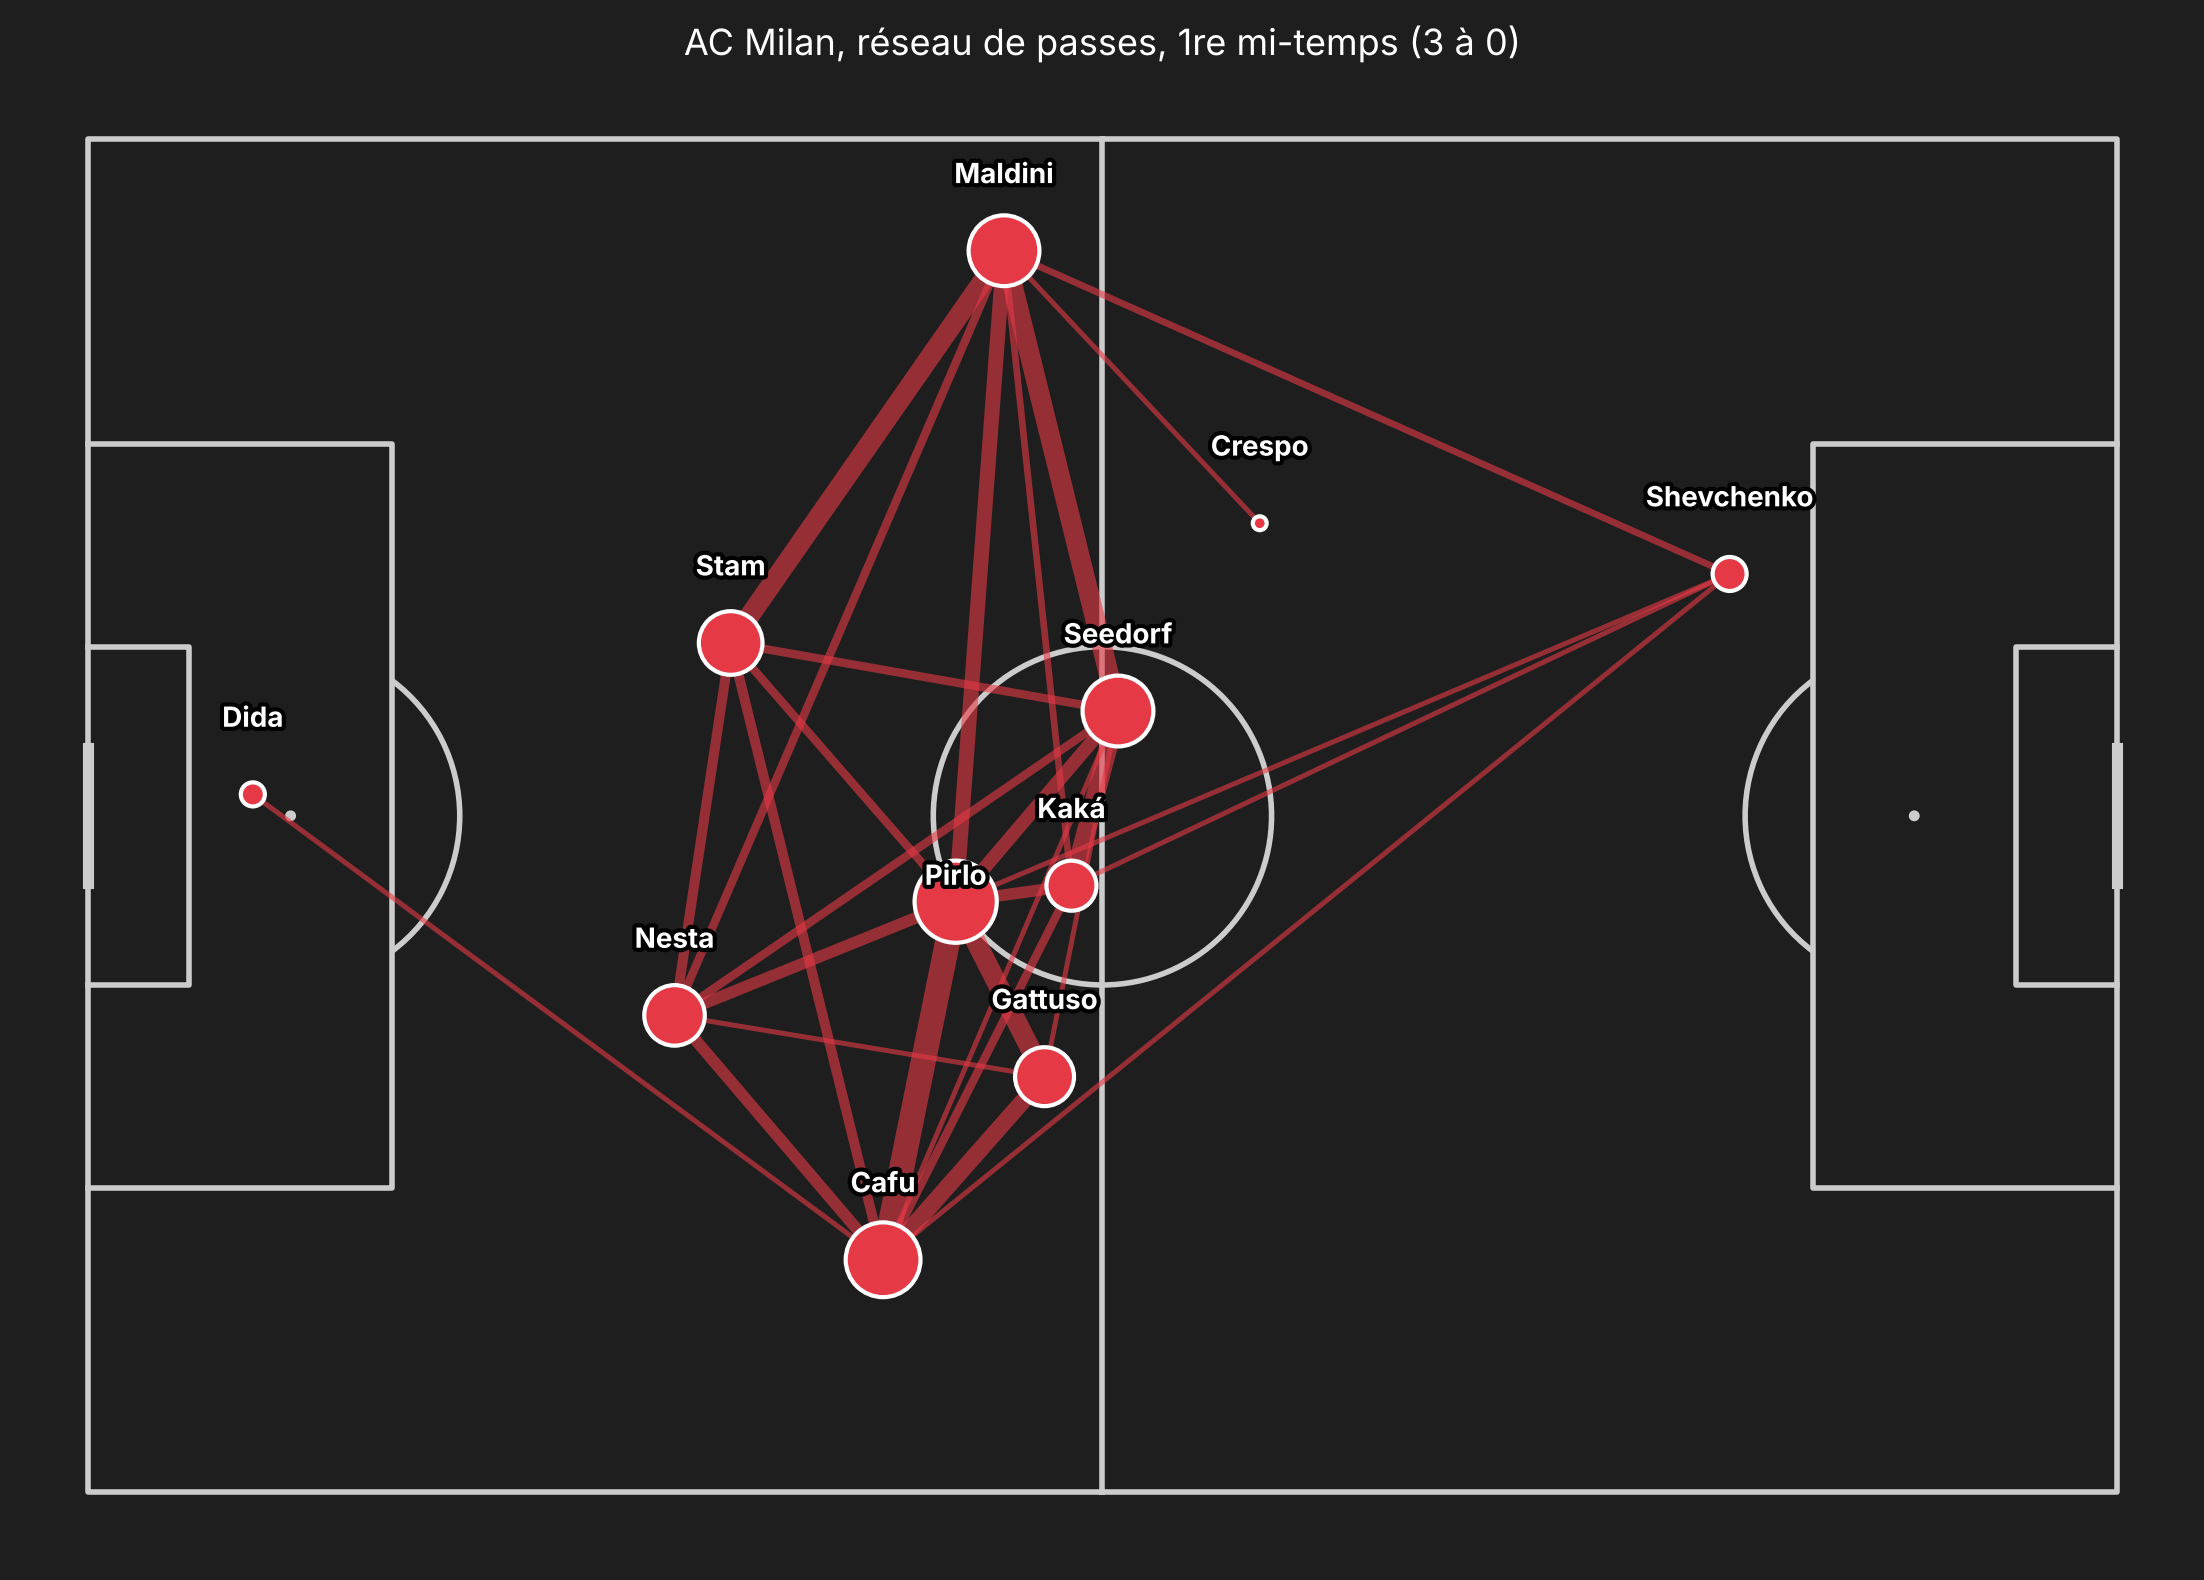

,x,y,nb_passes
passeur,,,
Pirlo,51.322857,45.077143,35
Cafu,47.031034,66.248276,29
Maldini,54.180769,6.588462,26
Seedorf,60.919231,33.803846,26
Stam,38.019048,29.780952,21
Nesta,34.700000,51.800000,19
Gattuso,56.577778,55.422222,18
Kaká,58.169231,44.130769,13
Shevchenko,97.083333,25.700000,6


In [12]:
pitch = Pitch(pitch_type="statsbomb", pitch_color="#1e1e1e", line_color="#cccccc")  # terrain StatsBomb (120 x 80), fond sombre
fig, ax = pitch.draw(figsize=(12, 8))                                              # un terrain
milan_mt1 = reseau_passes("AC Milan", 1, "#e63946", ax,                            # réseau de passes de Milan
                          "AC Milan, réseau de passes, 1re mi-temps (3 à 0)")
fig.set_facecolor("#1e1e1e")                                                       # fond de l'image assorti au terrain
plt.savefig("reseau_passes_milan_mt1.png", dpi=150, bbox_inches="tight")           # sauvegarde l'image
plt.show()                                                                          # affiche
milan_mt1.sort_values("nb_passes", ascending=False)                                # joueurs du plus impliqué au moins impliqué

### La construction des trois buts de Milan

Flèches rouges : passes. Pointillés blancs : conduites de balle. Flèche jaune : le tir.

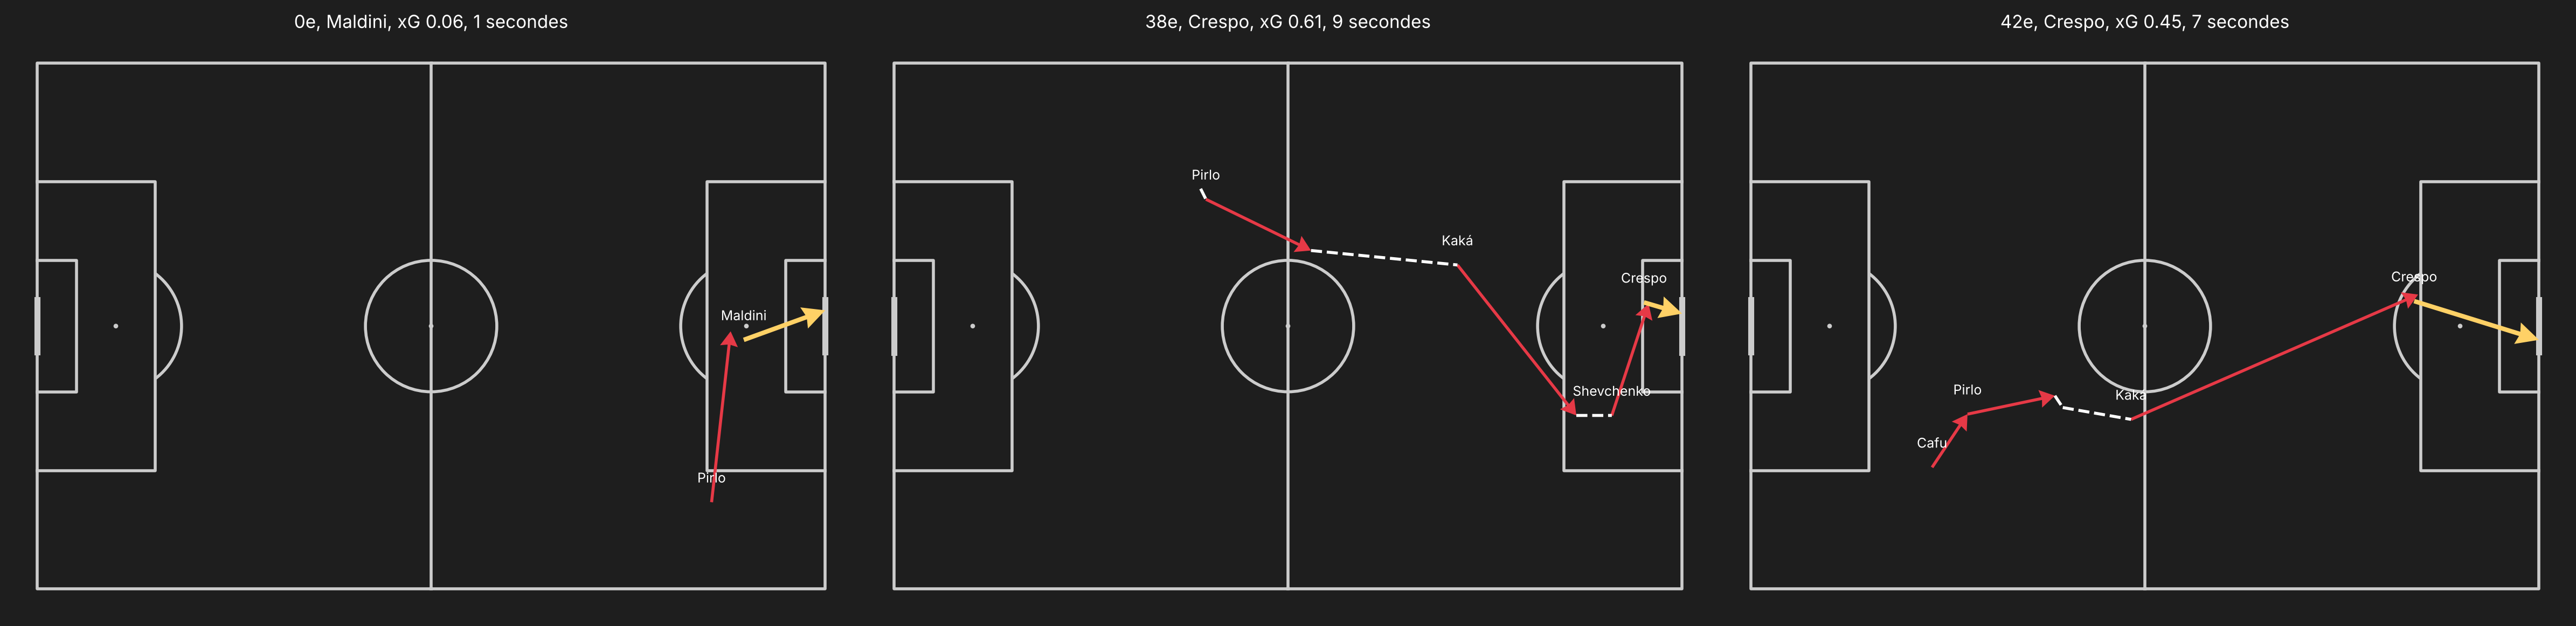

In [13]:
buts_milan = df[(df["type_name"] == "Shot") & (df["shot_outcome_name"] == "Goal")    # les tirs devenus buts
                & (df["team_name"] == "AC Milan") & (df["period"] <= 2)]             # de Milan, dans le temps réglementaire

pitch = Pitch(pitch_type="statsbomb", pitch_color="#1e1e1e", line_color="#cccccc")  # terrain StatsBomb
fig, axes = pitch.draw(nrows=1, ncols=3, figsize=(24, 6))                          # trois terrains côte à côte
for ax, (_, tir) in zip(axes, buts_milan.iterrows()):                              # un terrain par but
    dessiner_but(tir, ax, "#e63946")                                               # construction du but en rouge Milan
fig.set_facecolor("#1e1e1e")                                                       # fond assorti
plt.savefig("buts_milan_mt1.png", dpi=150, bbox_inches="tight")                    # sauvegarde
plt.show()                                                                          # affiche

In [14]:
for _, tir in buts_milan.iterrows():                                          # pour chaque but de Milan
    seq = df[(df["possession"] == tir["possession"])                          # actions de la même possession
             & (df["type_name"].isin(["Pass", "Carry", "Shot"]))              # passes, conduites et tirs
             & (df["index"] <= tir["index"])].tail(7).copy()                  # les 7 dernières jusqu'au tir
    seq["joueur"] = seq["player_name"].map(noms_courts)                       # nom court du joueur
    seq["x"] = seq["location"].str[0].round(0)                                # hauteur de l'action sur le terrain
    seq["profondeur"] = seq["pass_through_ball"].fillna(False).astype(bool)   # passe en profondeur ?
    print(f"BUT de la {tir['minute']}e minute ({tir['play_pattern_name']})")  # titre : minute et origine de l'action
    print(seq[["minute", "second", "type_name", "joueur", "x", "profondeur"]].to_string(index=False))  # le détail
    print()                                                                   # ligne vide entre deux buts

BUT de la 0e minute (From Free Kick)
 minute  second type_name  joueur     x  profondeur
      0      50      Pass   Pirlo 103.0       False
      0      51      Shot Maldini 108.0       False

BUT de la 38e minute (Regular Play)
 minute  second type_name     joueur     x  profondeur
     38       3     Carry      Pirlo  47.0       False
     38       3      Pass      Pirlo  48.0       False
     38       4     Carry       Kaká  64.0       False
     38       8      Pass       Kaká  86.0        True
     38      10     Carry Shevchenko 104.0       False
     38      11      Pass Shevchenko 109.0       False
     38      12      Shot     Crespo 114.0       False

BUT de la 42e minute (Regular Play)
 minute  second type_name joueur     x  profondeur
     42      50      Pass   Cafu  28.0       False
     42      51     Carry  Pirlo  33.0       False
     42      51      Pass  Pirlo  33.0       False
     42      52     Carry   Kaká  46.0       False
     42      53     Carry   Kaká  48.0

### Conclusion de la partie 1

Milan ne domine pas la première mi-temps par la possession (256 passes contre 250), mais par la vitesse de ses attaques. Sur les deux buts de Crespo, le schéma est identique : Pirlo lance l'action, Kaká conduit le ballon puis fait une passe en profondeur en diagonale (vers Shevchenko à la 38e, directement vers Crespo à la 42e), et Crespo conclut en 9 puis 7 secondes. Kaká est le joueur qui casse les lignes de Liverpool.

## Partie 2 : pourquoi Liverpool craque

### Les actions de Liverpool juste avant les buts de Crespo

Rappel : chaque équipe attaque vers la droite dans les données, donc un x élevé pour Liverpool veut dire que Liverpool est près du but de Milan.

In [15]:
for _, tir in buts_milan[buts_milan["minute"] > 0].iterrows():        # les deux buts de Crespo (on laisse le coup franc de côté)
    debut = df[df["possession"] == tir["possession"]]["index"].min()  # première action de la possession milanaise qui mène au but
    avant = df[(df["index"] < debut) & (df["team_name"] == "Liverpool")].tail(4).copy()  # les 4 dernières actions de Liverpool
    avant["joueur"] = avant["player_name"].map(noms_courts)            # nom court du joueur
    avant["x"] = avant["location"].str[0].round(0)                     # hauteur de l'action (repère Liverpool)
    print(f"Avant le but de la {tir['minute']}e minute")               # titre
    print(avant[["minute", "second", "type_name", "joueur", "x", "pass_outcome_name"]].to_string(index=False))  # le détail
    print()                                                            # ligne vide

Avant le but de la 38e minute
 minute  second     type_name joueur     x pass_outcome_name
     37      51          Pass Šmicer  71.0               NaN
     37      53 Ball Receipt* García 102.0               NaN
     37      53         Carry García 102.0               NaN
     37      54       Dribble García 106.0               NaN

Avant le but de la 42e minute
 minute  second     type_name  joueur    x pass_outcome_name
     42      46 Ball Receipt* Gerrard 65.0               NaN
     42      46         Carry Gerrard 65.0               NaN
     42      47          Pass Gerrard 65.0        Incomplete
     42      48 Ball Receipt*   Baroš 93.0               NaN



### Kaká reçoit il le ballon sous pression ?

StatsBomb indique pour chaque action si le joueur était sous pression (un adversaire au contact ou qui fond sur lui).

In [16]:
receptions_kaka = df[(df["player_name"] == KAKA)                                 # actions de Kaká
                     & (df["type_name"] == "Ball Receipt*")                      # seulement ses réceptions de balle
                     & (df["period"] <= 2)].copy()                               # dans le temps réglementaire
receptions_kaka["sous_pression"] = receptions_kaka["under_pressure"].fillna(False).astype(bool)  # case vide = pas de pression
receptions_kaka["camp_adverse"] = receptions_kaka["location"].str[0] > 60        # réception dans le camp de Liverpool ?
receptions_kaka.groupby("period").agg(                                           # résumé par mi-temps
    receptions=("sous_pression", "count"),                                       # nombre de ballons reçus
    sous_pression=("sous_pression", "sum"),                                      # dont sous pression
    dans_le_camp_adverse=("camp_adverse", "sum"),                                # dont dans le camp de Liverpool
)

,receptions,sous_pression,dans_le_camp_adverse
period,,,
1,26,3,13
2,32,2,25


### Les réceptions et les conduites de balle de Kaká en première mi-temps

Ronds blancs : réception libre. Ronds rouges : réception sous pression. Pointillés jaunes : conduites de balle de plus de 10 mètres vers l'avant. Milan attaque vers la droite.

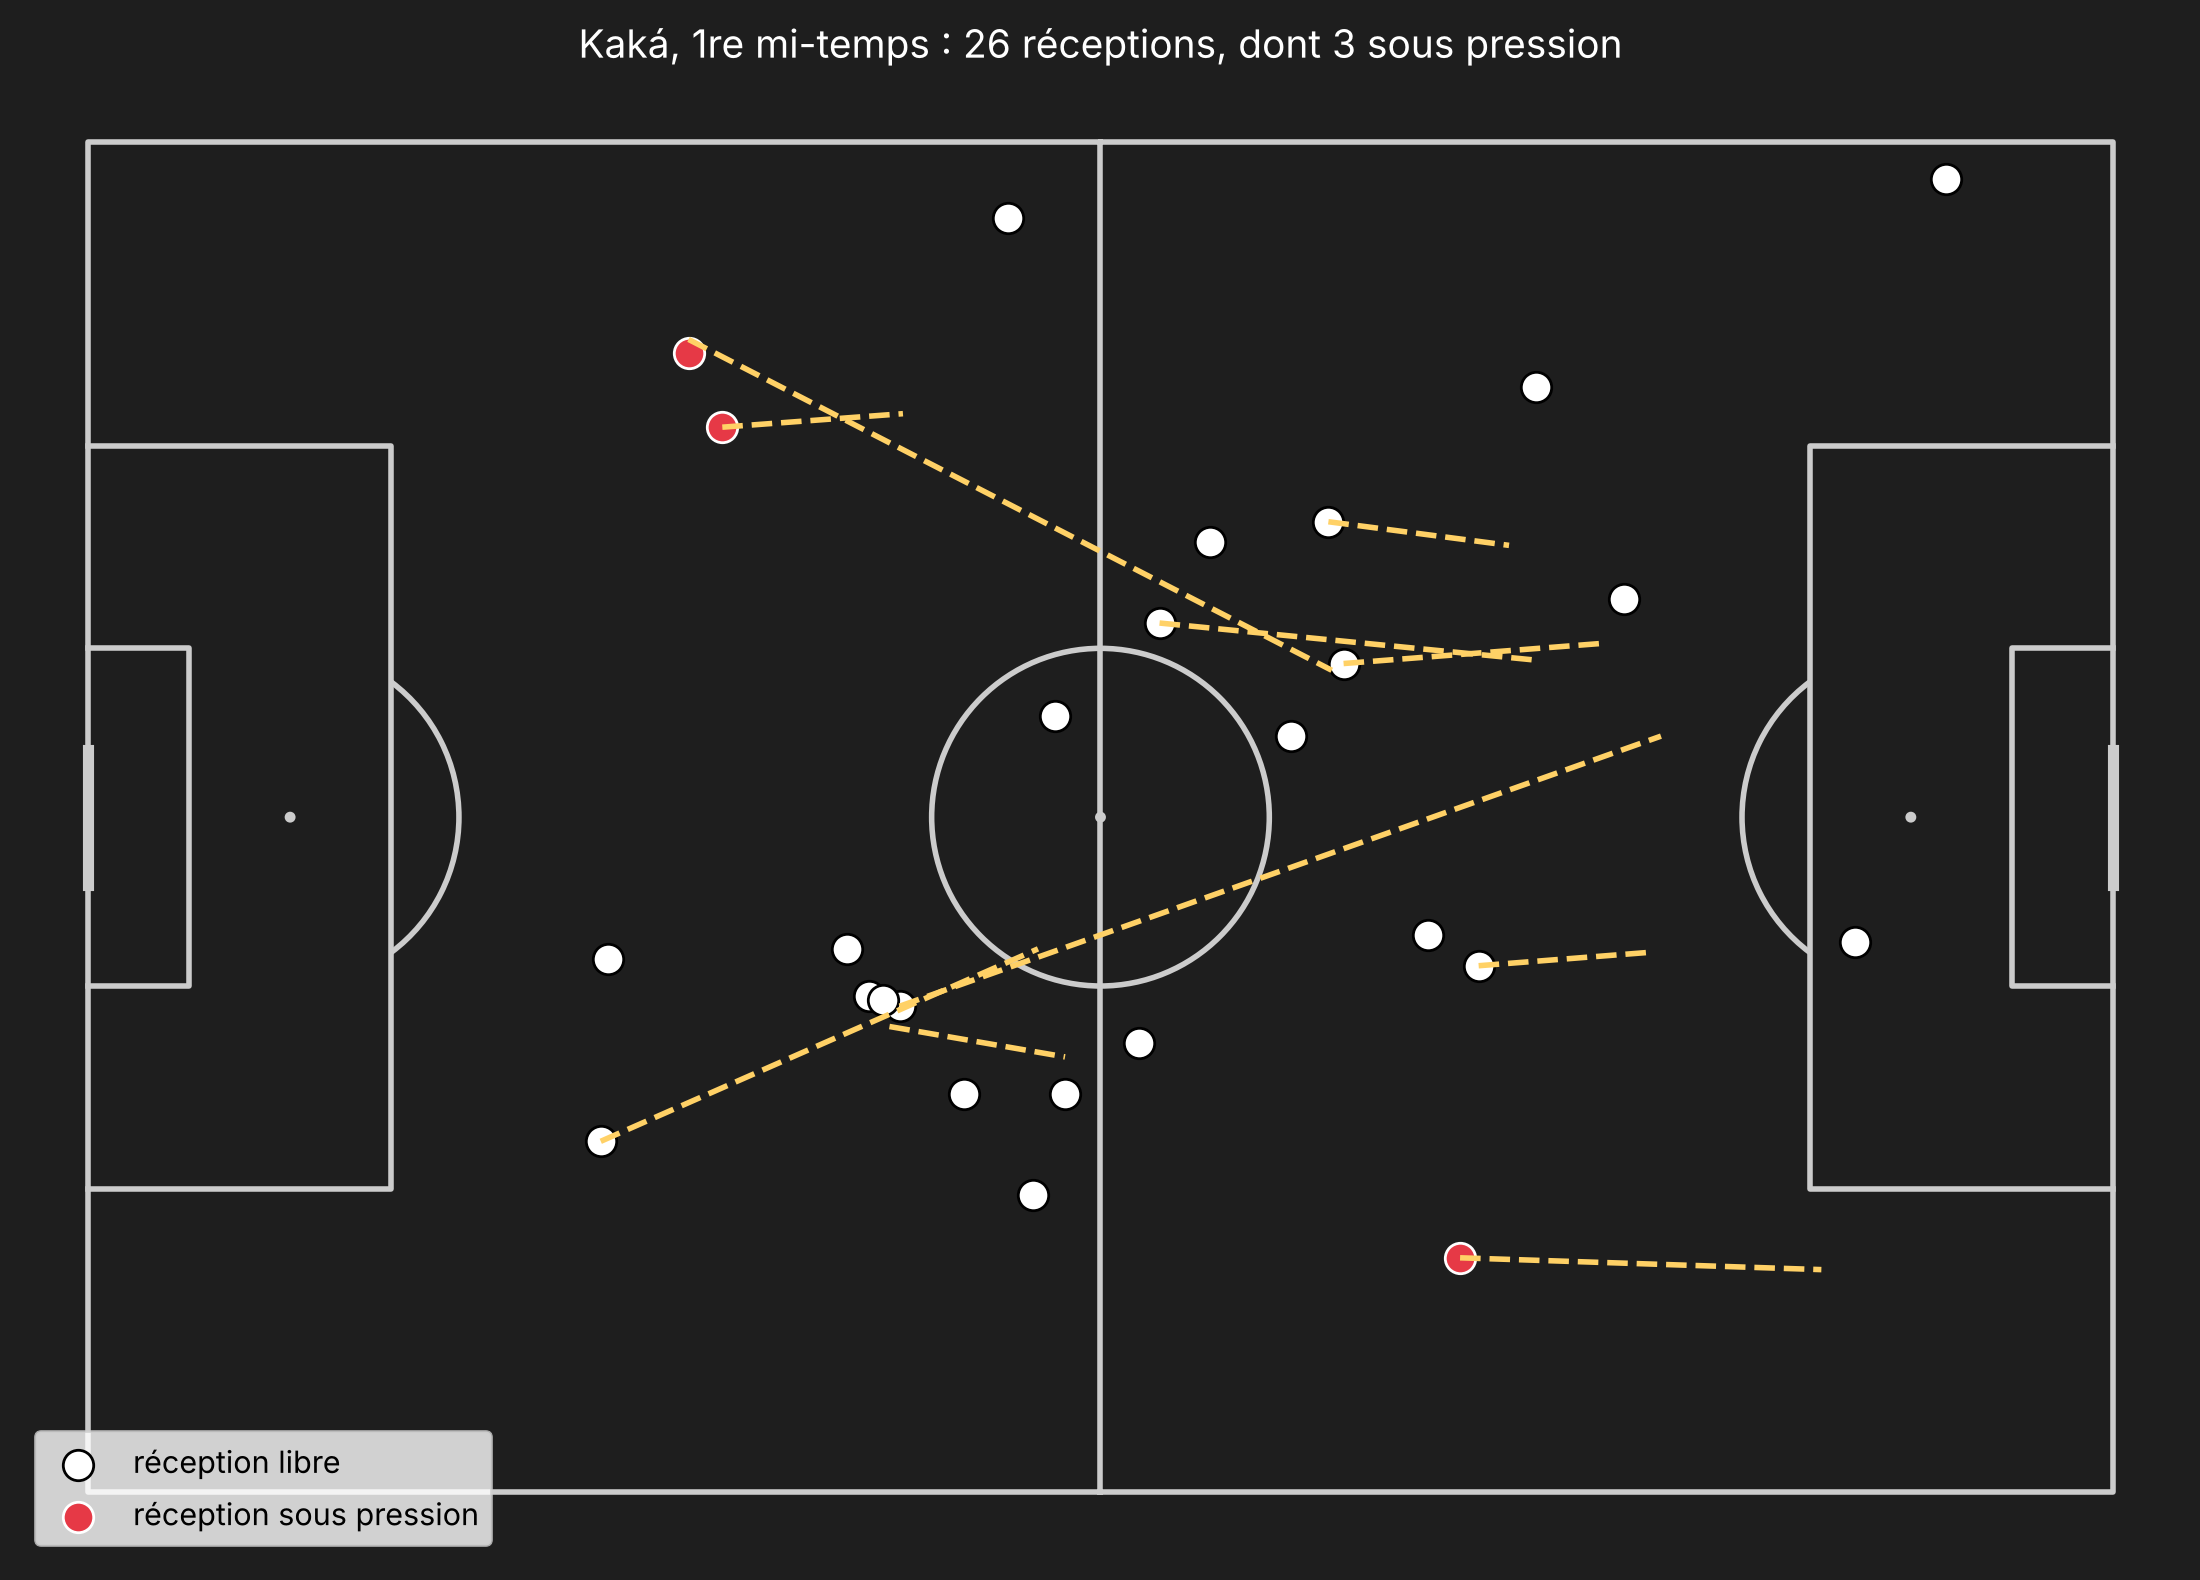

In [17]:
mt1 = receptions_kaka[receptions_kaka["period"] == 1]                         # réceptions de la première mi-temps
conduites = df[(df["player_name"] == KAKA)                                    # actions de Kaká
               & (df["type_name"] == "Carry") & (df["period"] == 1)].copy()   # ses conduites de balle en première mi-temps
conduites["gain"] = conduites["carry_end_location"].str[0] - conduites["location"].str[0]  # mètres gagnés vers l'avant
conduites = conduites[conduites["gain"] > 10]                                 # conduites de plus de 10 mètres

pitch = Pitch(pitch_type="statsbomb", pitch_color="#1e1e1e", line_color="#cccccc")  # terrain StatsBomb
fig, ax = pitch.draw(figsize=(12, 8))                                              # un seul terrain
for _, c in conduites.iterrows():                                                  # chaque grande conduite de balle
    pitch.lines(c["location"][0], c["location"][1],                                # départ de la conduite
                c["carry_end_location"][0], c["carry_end_location"][1],            # arrivée de la conduite
                lw=2, linestyle="--", color="#ffd166", ax=ax)                      # pointillés jaunes
libres = mt1[~mt1["sous_pression"]]                                                # réceptions sans pression
pressees = mt1[mt1["sous_pression"]]                                               # réceptions sous pression
pitch.scatter(libres["location"].str[0], libres["location"].str[1], s=120,         # ronds blancs
              color="white", edgecolors="black", ax=ax, label="réception libre")
pitch.scatter(pressees["location"].str[0], pressees["location"].str[1], s=120,     # ronds rouges
              color="#e63946", edgecolors="white", ax=ax, label="réception sous pression")
ax.legend(loc="lower left", fontsize=11)                                           # légende
ax.set_title(f"Kaká, 1re mi-temps : {len(mt1)} réceptions, dont {len(pressees)} sous pression",  # titre avec les chiffres
             color="white", fontsize=14)
fig.set_facecolor("#1e1e1e")                                                       # fond assorti
plt.savefig("kaka_receptions_mt1.png", dpi=150, bbox_inches="tight")               # sauvegarde
plt.show()                                                                          # affiche

### Où Liverpool perd le ballon

Une perte de balle, ici, c'est une passe ratée, un ballon perdu dans un duel (Dispossessed) ou un mauvais contrôle (Miscontrol).

In [18]:
liv = df[(df["team_name"] == "Liverpool") & (df["period"] <= 2)].copy()       # actions de Liverpool, temps réglementaire
perte = (((liv["type_name"] == "Pass") & liv["pass_outcome_name"].isin(["Incomplete", "Out"]))  # passe ratée ou sortie
         | liv["type_name"].isin(["Dispossessed", "Miscontrol"]))              # ou ballon perdu, ou mauvais contrôle
pertes_liv = liv[perte].copy()                                                 # on garde les pertes de balle
pertes_liv["tiers"] = pd.cut(pertes_liv["location"].str[0], bins=[0, 40, 80, 120],  # tiers du terrain selon la hauteur x
                             labels=["défensif", "milieu", "offensif"])
pd.crosstab(pertes_liv["period"], pertes_liv["tiers"], margins=True, margins_name="total")  # pertes par mi-temps et par tiers

tiers,défensif,milieu,offensif,total
period,,,,
1,13,36,19,68
2,14,24,19,57
total,27,60,38,125


### Conclusion de la partie 2

Du côté de Liverpool, le problème principal est Kaká : il est beaucoup trop libre. Il reçoit 26 ballons (13 dans son camp, 13 dans le camp adverse) et n'est mis sous pression que 3 fois, ce qui lui laisse le temps de faire 10 conduites de balle de plus de 10 mètres. Personne ne l'attaque réellement. Liverpool perd aussi la guerre du milieu : 36 de ses 68 pertes de balle ont lieu dans cette zone. Milan punit chaque erreur très vite : après une attaque perdue de García à la 38e, puis une passe ratée de Gerrard à la 42e, Milan marque 18 puis 9 secondes après avoir récupéré le ballon.

## Partie 3 : pourquoi Milan craque en deuxième mi-temps

### Le changement de Benítez vu dans les réseaux de passes de Liverpool

À la pause, Hamann entre à la place de Finnan. En première mi-temps, Kewell sort blessé à la 22e minute et Šmicer le remplace : les deux apparaissent sur le premier dessin. Liverpool attaque vers la droite.

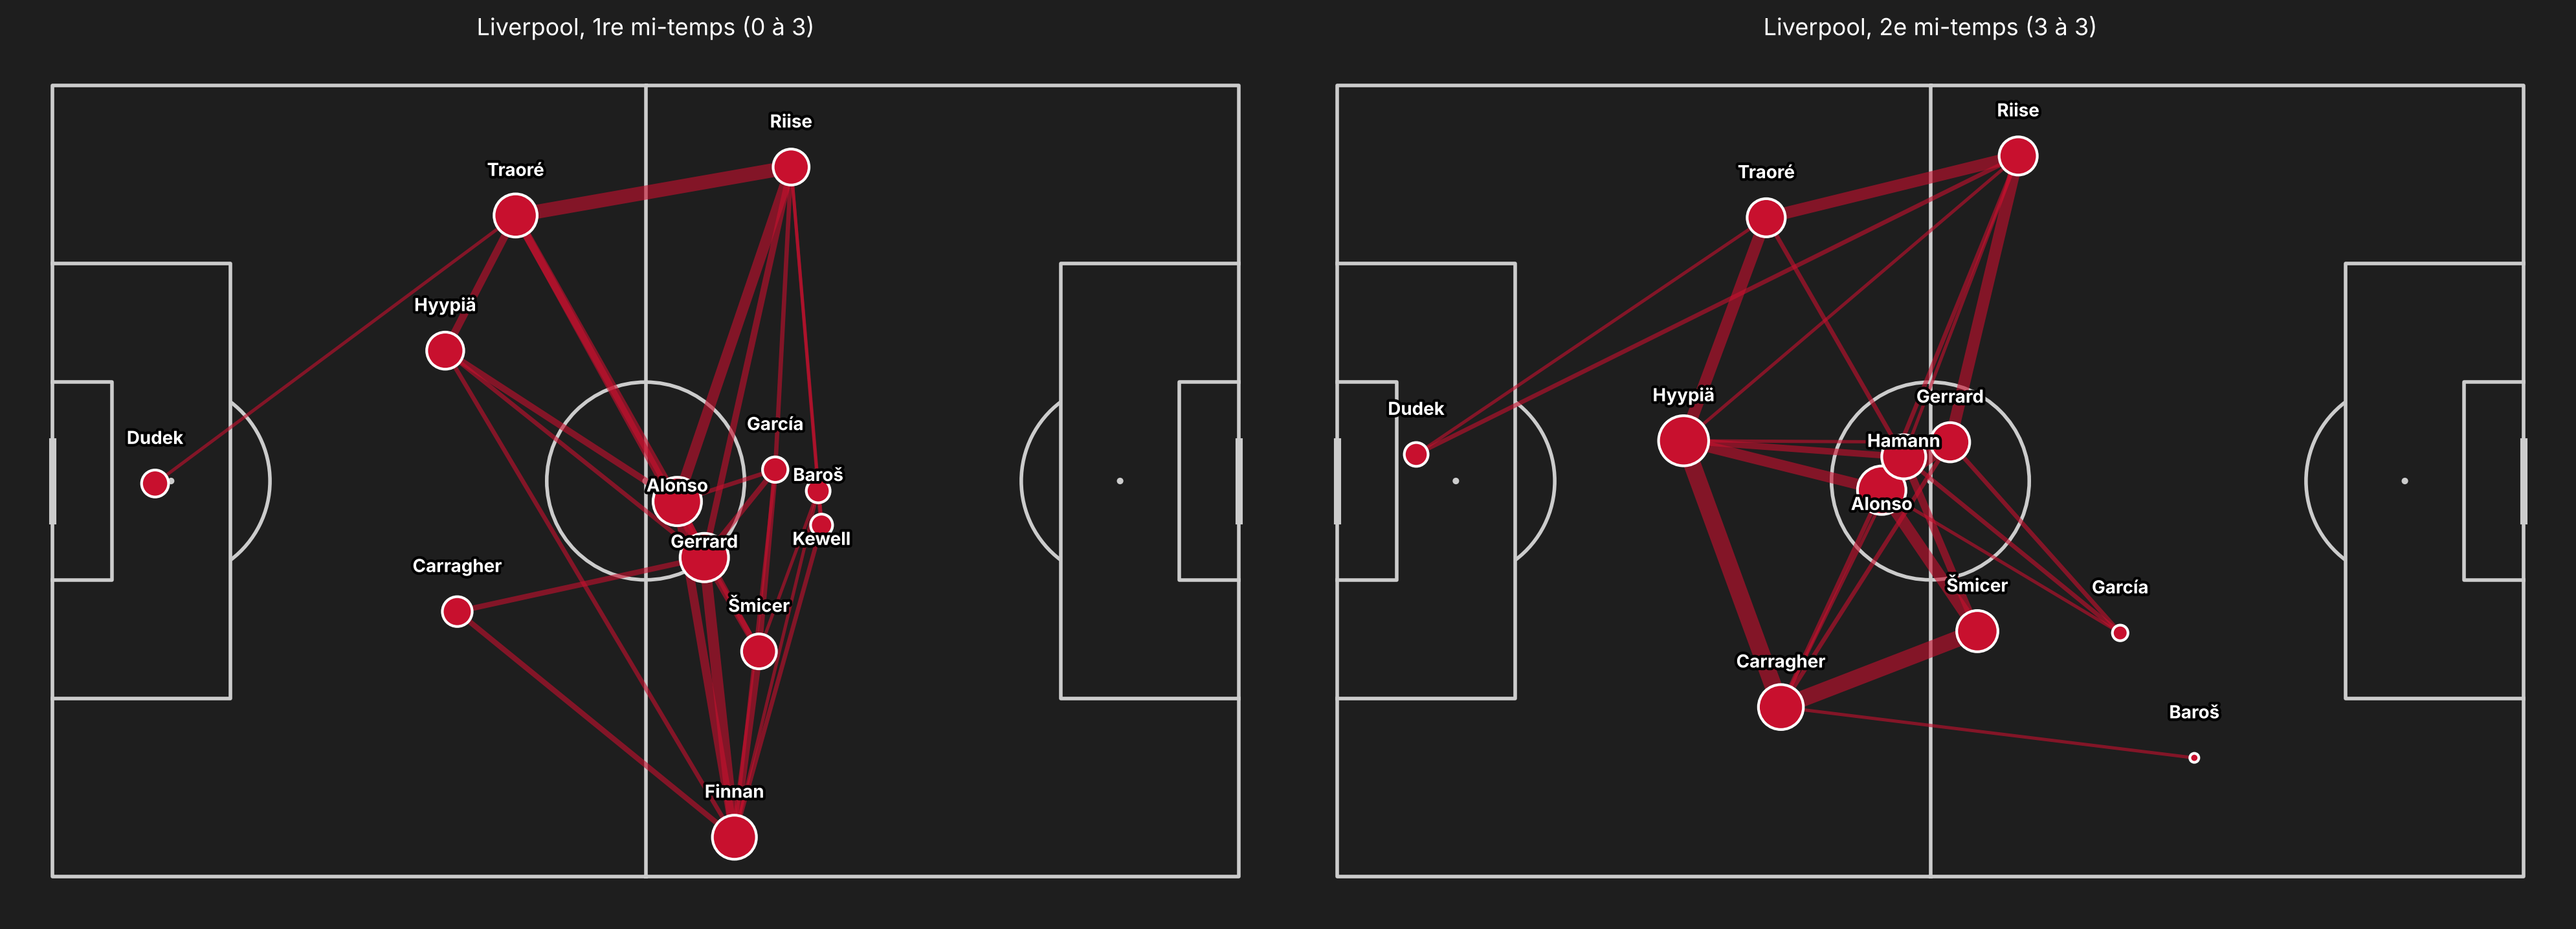

In [19]:
pitch = Pitch(pitch_type="statsbomb", pitch_color="#1e1e1e", line_color="#cccccc")  # terrain StatsBomb
fig, axes = pitch.draw(nrows=1, ncols=2, figsize=(20, 8))                          # deux terrains côte à côte
liv_mt1 = reseau_passes("Liverpool", 1, "#c8102e", axes[0], "Liverpool, 1re mi-temps (0 à 3)")  # terrain de gauche
liv_mt2 = reseau_passes("Liverpool", 2, "#c8102e", axes[1], "Liverpool, 2e mi-temps (3 à 3)")   # terrain de droite
fig.set_facecolor("#1e1e1e")                                                      # fond assorti
plt.savefig("reseau_passes_liverpool_mt1_mt2.png", dpi=150, bbox_inches="tight")  # sauvegarde
plt.show()                                                                         # affiche

In [20]:
comparaison = liv_mt1.join(liv_mt2, lsuffix="_mt1", rsuffix="_mt2", how="outer")  # on assemble les deux tableaux joueur par joueur
comparaison[["x_mt1", "x_mt2", "nb_passes_mt1", "nb_passes_mt2"]].round(1).sort_values("x_mt2")  # hauteur (x) et passes, du plus bas au plus haut

,x_mt1,x_mt2,nb_passes_mt1,nb_passes_mt2
passeur,,,,
Dudek,10.4,8.0,9.0,7.0
Hyypiä,39.7,35.0,17.0,31.0
Traoré,46.8,43.4,23.0,18.0
Carragher,40.9,44.9,11.0,25.0
Alonso,63.2,55.1,29.0,29.0
Hamann,NaN,57.3,NaN,24.0
Gerrard,65.9,62.0,29.0,19.0
Šmicer,71.5,64.7,15.0,21.0
Riise,74.7,68.9,16.0,18.0


### Kaká, première mi-temps contre deuxième mi-temps

Kaká n'est pas plus pressé en deuxième mi-temps. On compte donc ses actions dangereuses pour voir s'il fait autant de dégâts.

In [21]:
def actions_joueur(nom_complet, periode):
    a = df[(df["player_name"] == nom_complet) & (df["period"] == periode)]   # actions du joueur pendant la période
    passes = a[a["type_name"] == "Pass"]                                     # ses passes
    conduites = a[a["type_name"] == "Carry"]                                 # ses conduites de balle
    gain = conduites["carry_end_location"].str[0] - conduites["location"].str[0]  # mètres gagnés vers l'avant par conduite
    return {                                                                 # un dictionnaire = une colonne du tableau final
        "passes": len(passes),                                               # nombre de passes
        "passes réussies": passes["pass_outcome_name"].isna().sum(),         # réussies = case "résultat" vide
        "passes en profondeur": passes["pass_through_ball"].fillna(False).astype(bool).sum(),  # passes dans le dos de la défense
        "passes menant à un tir": passes["pass_shot_assist"].fillna(False).astype(bool).sum(),  # passes suivies d'un tir
        "conduites de plus de 10 m": (gain > 10).sum(),                      # grandes conduites de balle
        "tirs": (a["type_name"] == "Shot").sum(),                            # tirs tentés
    }

pd.DataFrame({"1re mi-temps": actions_joueur(KAKA, 1),                     # colonne première mi-temps
              "2e mi-temps": actions_joueur(KAKA, 2)})                     # colonne deuxième mi-temps

,1re mi-temps,2e mi-temps
passes,18,24
passes réussies,13,18
passes en profondeur,4,0
passes menant à un tir,0,1
conduites de plus de 10 m,10,4
tirs,1,3


### Le bloc défensif de Liverpool face à Kaká

Position moyenne de chaque joueur de Liverpool quand il fait une action défensive (pressing, duel, interception, contre, dégagement, récupération, faute), vue dans le sens d'attaque de Milan, avec les réceptions de Kaká par dessus. Quand un joueur est remplacé pendant la mi-temps, on garde celui des deux qui a joué le plus longtemps (Šmicer plutôt que Kewell, Baroš plutôt que Cissé).

Limite : chaque joueur ne fait qu'une dizaine à une vingtaine d'actions défensives par mi-temps, ces positions donnent donc une tendance, pas un placement exact. En première mi-temps, Riise et Šmicer apparaissent très haut parce qu'ils pressaient souvent dans le camp de Milan.

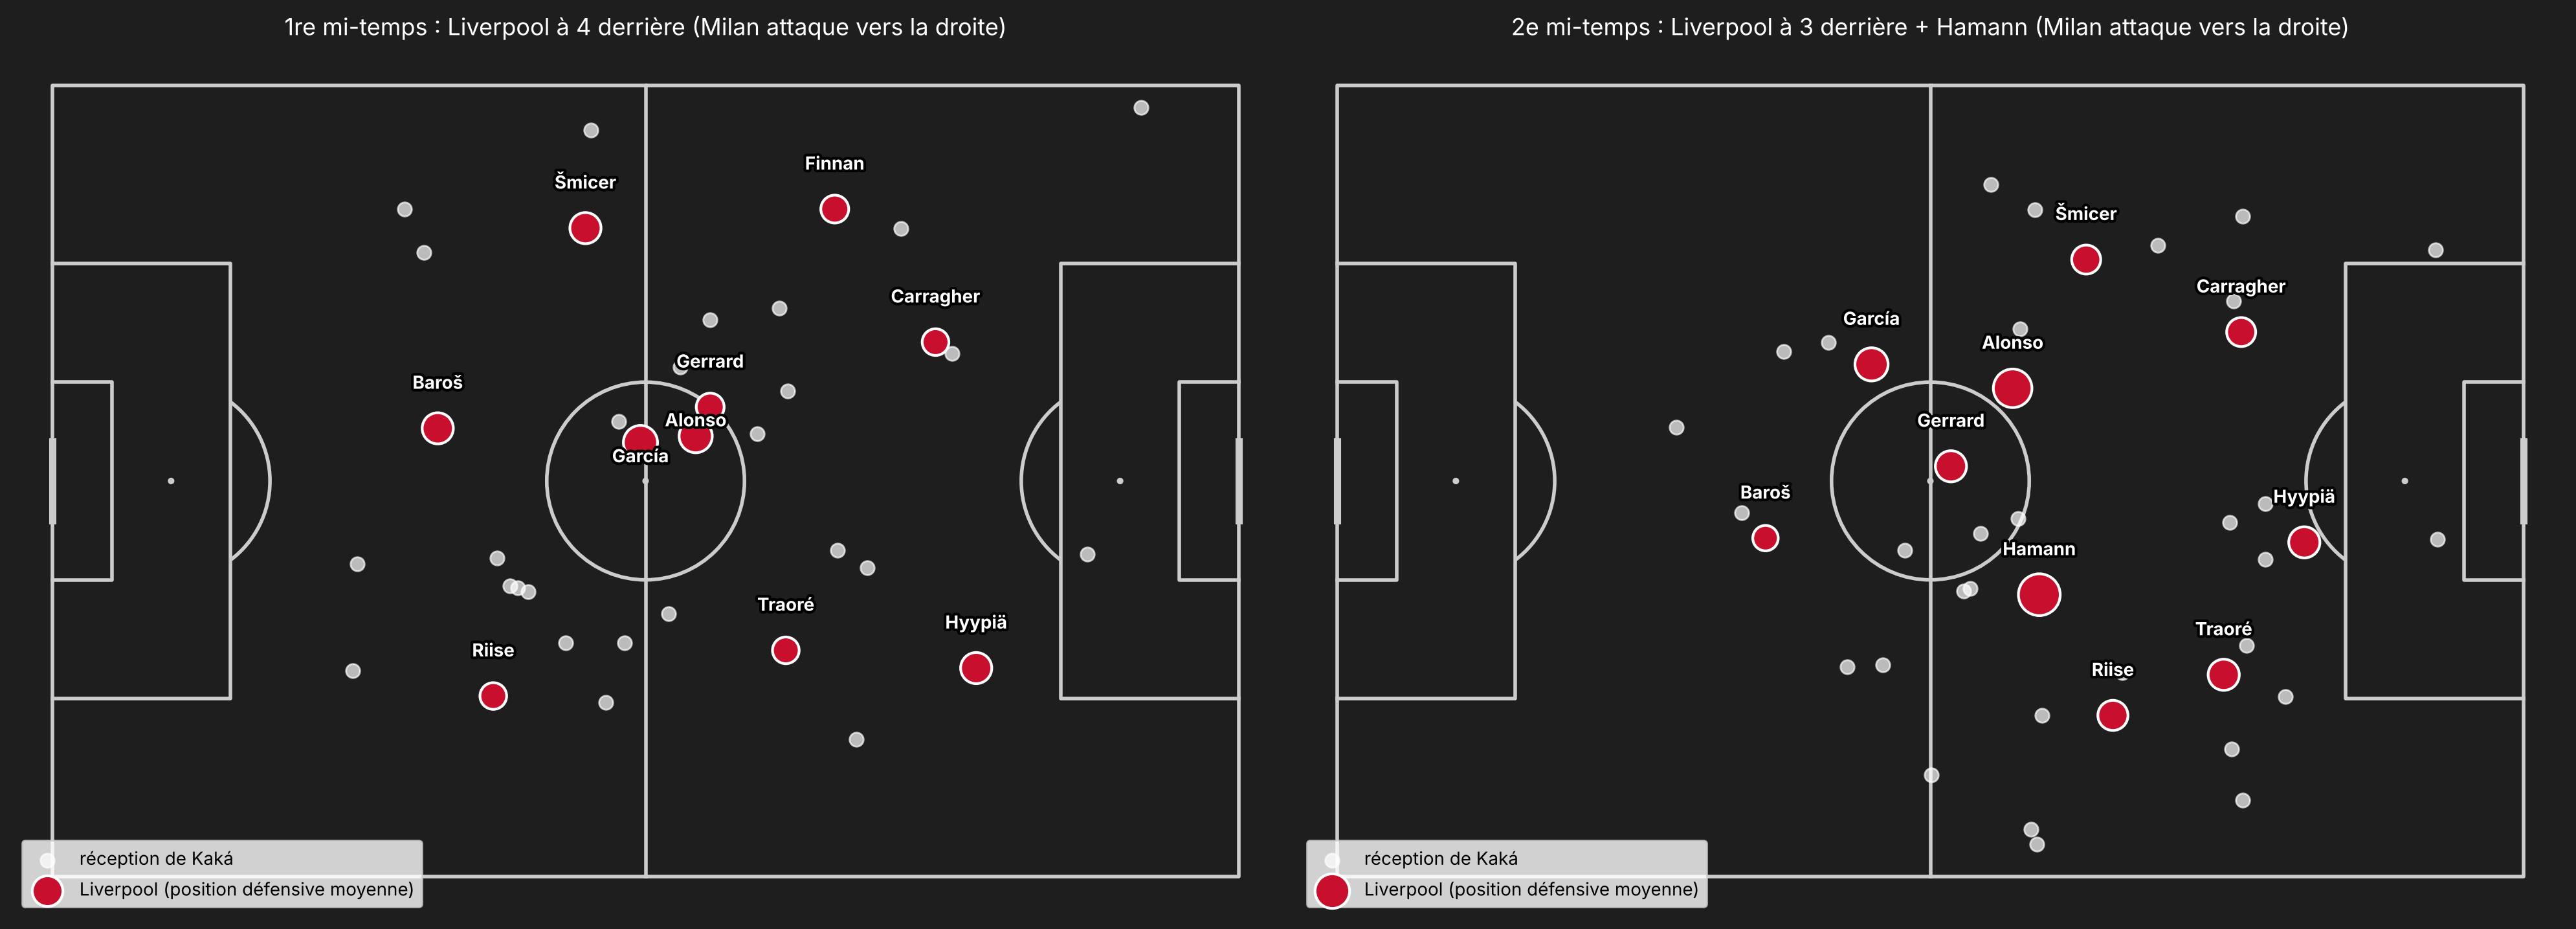

In [22]:
pitch = Pitch(pitch_type="statsbomb", pitch_color="#1e1e1e", line_color="#cccccc")  # terrain StatsBomb
fig, axes = pitch.draw(nrows=1, ncols=2, figsize=(20, 8))                          # deux terrains côte à côte
for ax, periode, titre in [(axes[0], 1, "1re mi-temps : Liverpool à 4 derrière"),        # terrain de gauche
                           (axes[1], 2, "2e mi-temps : Liverpool à 3 derrière + Hamann")]:  # terrain de droite
    bloc = bloc_defensif("Liverpool", periode)                                        # positions défensives de Liverpool
    bloc = bloc[bloc.index != "Dudek"]                                                # on enlève le gardien pour la lisibilité
    k = receptions_kaka[receptions_kaka["period"] == periode]                         # réceptions de Kaká dans la mi-temps
    pitch.scatter(k["location"].str[0], k["location"].str[1], s=60, color="white",    # petits ronds blancs = réceptions de Kaká
                  alpha=0.7, ax=ax, label="réception de Kaká")
    pitch.scatter(bloc["x"], bloc["y"], s=bloc["actions"] * 20, color="#c8102e",      # ronds rouges = joueurs de Liverpool
                  edgecolors="white", linewidth=1.5, ax=ax, label="Liverpool (position défensive moyenne)")
    ecrire_noms(bloc, ax)                                                             # noms sans chevauchement
    ax.set_title(f"{titre} (Milan attaque vers la droite)", color="white", fontsize=13)  # titre
    ax.legend(loc="lower left", fontsize=10)                                          # légende
fig.set_facecolor("#1e1e1e")                                                          # fond assorti
plt.savefig("bloc_liverpool_vs_kaka.png", dpi=150, bbox_inches="tight")               # sauvegarde
plt.show()                                                                             # affiche

In [23]:
pd.DataFrame({"1re mi-temps": bloc_defensif("Liverpool", 1)["actions"],    # actions défensives par joueur en 1re mi-temps
              "2e mi-temps": bloc_defensif("Liverpool", 2)["actions"]}     # et en 2e mi-temps
            ).fillna(0).astype(int).sort_values("2e mi-temps", ascending=False)  # du plus actif au moins actif après la pause

,1re mi-temps,2e mi-temps
joueur,,
Hamann,0,27
Alonso,17,23
García,18,17
Gerrard,12,15
Traoré,11,15
Hyypiä,15,15
Riise,11,14
Carragher,11,13
Šmicer,15,13


### Milan tranche par tranche

Le match est découpé en tranches : la première mi-temps entière (référence), puis la deuxième mi-temps en quatre morceaux, dont les six minutes folles (53e à 60e). Les pertes et les pressings sont ramenés à la minute, car les tranches n'ont pas la même durée.

In [24]:
tranches = [("1re mi-temps", 1, 0, 50),            # (nom, période, minute de début, minute de fin) ; 50 pour inclure le temps additionnel
            ("45e à 52e", 2, 45, 52),
            ("53e à 60e (les 6 minutes)", 2, 53, 60),
            ("61e à 75e", 2, 61, 75),
            ("76e à 90e", 2, 76, 95)]               # 95 pour inclure le temps additionnel

lignes = []                                                                     # une ligne par tranche
for nom, periode, debut, fin in tranches:                                       # on passe chaque tranche en revue
    t = df[(df["team_name"] == "AC Milan") & (df["period"] == periode)          # actions de Milan dans la bonne période
           & (df["minute"].between(debut, fin))]                                # et entre les deux minutes
    passes = t[t["type_name"] == "Pass"]                                        # passes de Milan
    pertes = (passes["pass_outcome_name"].isin(["Incomplete", "Out"]).sum()     # passes ratées
              + t["type_name"].isin(["Dispossessed", "Miscontrol"]).sum())      # plus ballons perdus et mauvais contrôles
    minutes = t["minute"].nunique()                                             # durée réelle = nombre de minutes présentes dans les données
    lignes.append({"tranche": nom,                                              # nom de la tranche
                   "passes": len(passes),                                       # nombre de passes
                   "% réussies": round(passes["pass_outcome_name"].isna().mean() * 100),  # pourcentage de passes réussies
                   "pertes par minute": round(pertes / minutes, 2),             # pertes ramenées à la minute
                   "pressings par minute": round((t["type_name"] == "Pressure").sum() / minutes, 2)})  # pressings par minute

milan_tranches = pd.DataFrame(lignes).set_index("tranche")                      # tableau final, une ligne par tranche
milan_tranches                                                                  # affiche

,passes,% réussies,pertes par minute,pressings par minute
tranche,,,,
1re mi-temps,256,77,1.53,1.62
45e à 52e,51,82,1.50,2.38
53e à 60e (les 6 minutes),27,59,1.50,1.00
61e à 75e,64,81,1.20,1.87
76e à 90e,89,81,1.31,1.31


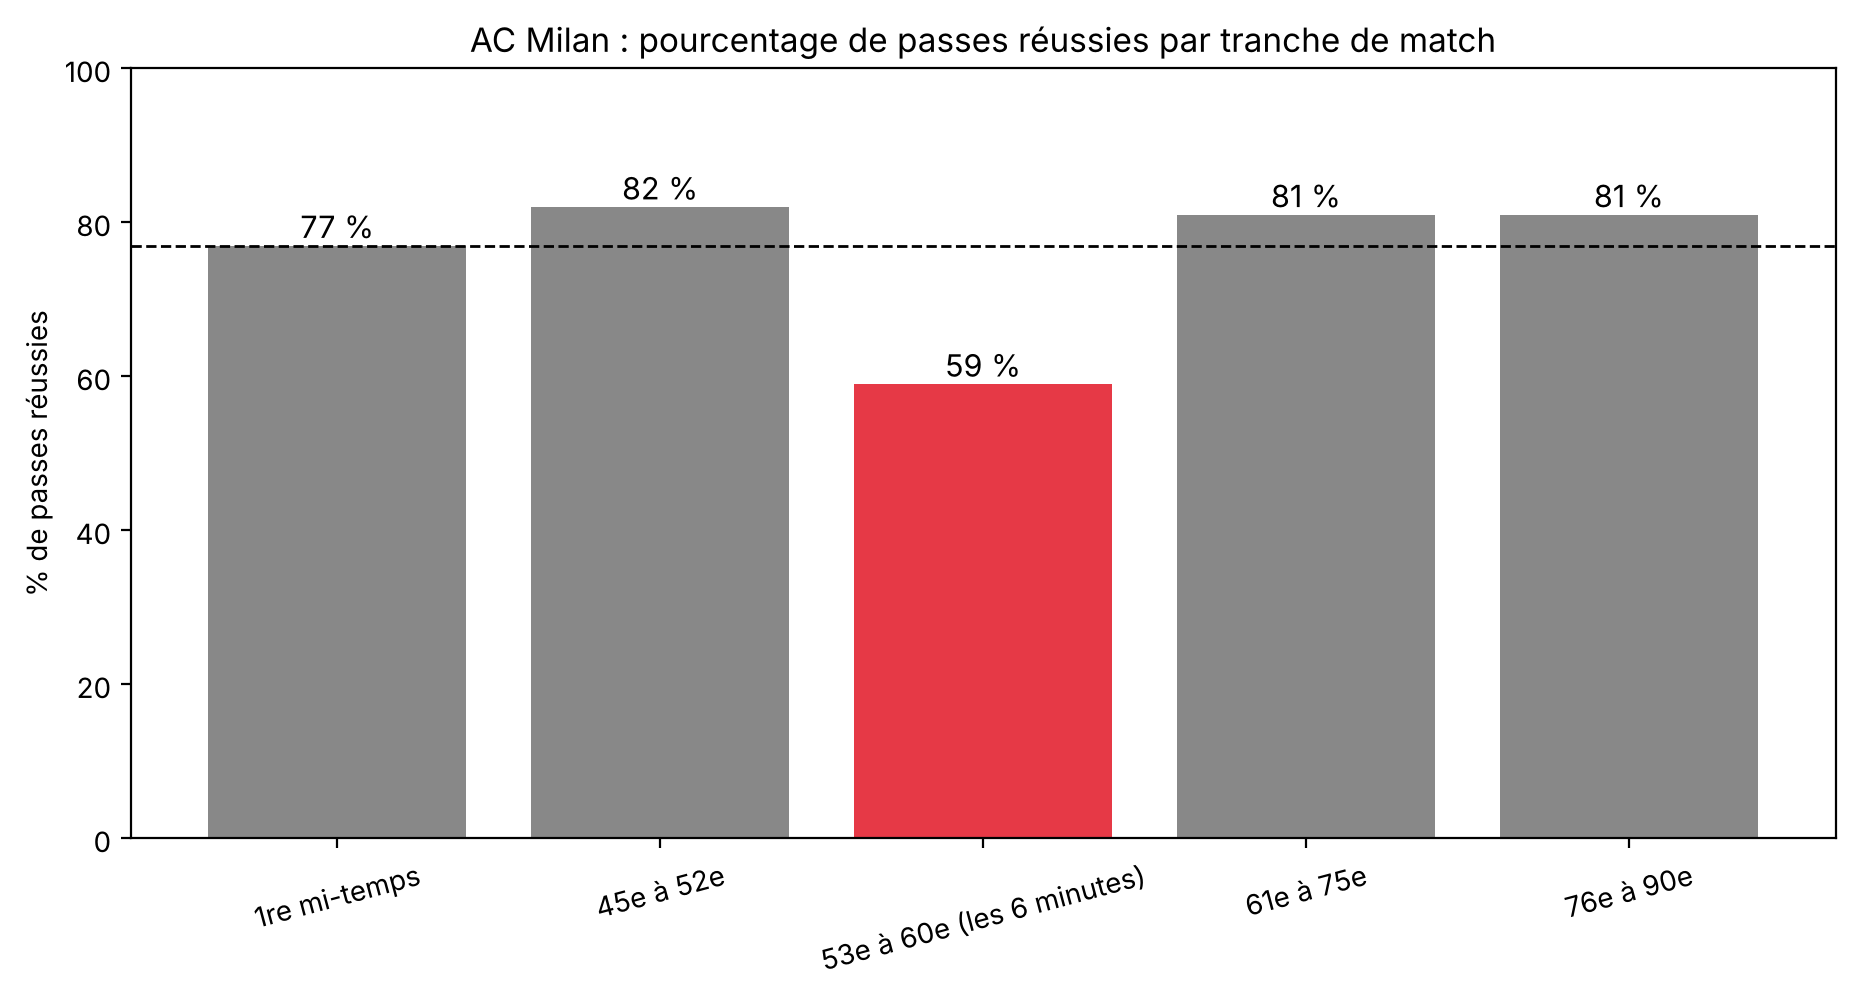

In [25]:
fig, ax = plt.subplots(figsize=(11, 5))                                          # une figure simple
couleurs = ["#888888" if "6 minutes" not in n else "#e63946" for n in milan_tranches.index]  # rouge pour les 6 minutes, gris sinon
ax.bar(milan_tranches.index, milan_tranches["% réussies"], color=couleurs)       # une barre par tranche
ax.axhline(milan_tranches.loc["1re mi-temps", "% réussies"], color="black",      # ligne de référence = première mi-temps
           linestyle="--", lw=1)
for i, v in enumerate(milan_tranches["% réussies"]):                             # valeur au dessus de chaque barre
    ax.text(i, v + 1, f"{v} %", ha="center", fontsize=11)
ax.set_ylim(0, 100)                                                              # axe de 0 à 100 %
ax.set_ylabel("% de passes réussies")                                            # titre de l'axe vertical
ax.set_title("AC Milan : pourcentage de passes réussies par tranche de match")   # titre du graphique
plt.xticks(rotation=15)                                                          # étiquettes légèrement inclinées
plt.savefig("milan_passes_tranches.png", dpi=150, bbox_inches="tight")           # sauvegarde
plt.show()                                                                        # affiche

### Milan met il de la pression sur les actions des buts de Liverpool ?

In [26]:
buts_liv = df[(df["type_name"] == "Shot") & (df["shot_outcome_name"] == "Goal")      # les buts
              & (df["team_name"] == "Liverpool") & (df["period"] == 2)]             # de Liverpool en deuxième mi-temps

for _, tir in buts_liv.iterrows():                                                   # pour chaque but de Liverpool
    seq = df[(df["possession"] == tir["possession"])                                 # actions de la même possession
             & (df["team_name"] == "Liverpool")                                      # seulement celles de Liverpool
             & (df["type_name"].isin(["Pass", "Carry", "Shot"]))                     # passes, conduites et tirs
             & (df["index"] <= tir["index"])].tail(8).copy()                         # les 8 dernières jusqu'au tir
    seq["joueur"] = seq["player_name"].map(noms_courts)                              # nom court
    seq["sous pression"] = seq["under_pressure"].fillna(False).astype(bool)          # pression milanaise sur l'action ?
    print(f"But de {noms_courts[tir['player_name']]} ({tir['minute']}e) : "          # titre
          f"{seq['sous pression'].sum()} action(s) sur {len(seq)} sous pression")    # résumé
    print(seq[["minute", "second", "type_name", "joueur", "sous pression"]].to_string(index=False))  # le détail
    print()                                                                          # ligne vide

But de Gerrard (53e) : 0 action(s) sur 8 sous pression
 minute  second type_name  joueur  sous pression
     52      54      Pass  Hamann          False
     52      55     Carry  Alonso          False
     52      56      Pass  Alonso          False
     52      58     Carry   Riise          False
     53       0      Pass   Riise          False
     53       1     Carry   Riise          False
     53       2      Pass   Riise          False
     53       4      Shot Gerrard          False

But de Šmicer (55e) : 2 action(s) sur 6 sous pression
 minute  second type_name joueur  sous pression
     54      57      Pass  Riise          False
     54      58      Pass Alonso          False
     54      59     Carry Hamann          False
     55       0      Pass Hamann          False
     55       1     Carry Šmicer           True
     55       2      Shot Šmicer           True

But de Alonso (59e) : 1 action(s) sur 2 sous pression
 minute  second type_name joueur  sous pression
     59   

### Conclusion de la partie 3

Milan ne craque pas à cause d'un marquage sur Kaká : il reste libre (2 réceptions sous pression sur 32), mais il ne casse plus les lignes (0 passe en profondeur contre 4, 4 grandes conduites de balle contre 10). Le passage de Liverpool à trois défenseurs centraux, avec Riise et Šmicer qui redescendent et le double pivot Hamann Alonso devant, ferme l'espace dans lequel Kaká courait en première mi-temps. Hamann devient le joueur le plus actif défensivement de Liverpool. Le vrai effondrement a lieu entre la 53e et la 60e minute, comme une absence : seulement 27 passes en 8 minutes contre 51 juste avant, 59 % de passes réussies contre environ 80 % le reste du match, et un pressing qui tombe à 1 par minute, le plus bas du match. Sur le but de Gerrard, aucune des 8 dernières actions de Liverpool n'est faite sous pression milanaise. À partir de la 61e minute, Milan retrouve son niveau habituel (81 % de passes réussies) et se relève.

Note sur le mental : les données ne mesurent pas le mental, mais elles montrent un comportement collectif qui ressemble à une déconnexion pendant ces 8 minutes. On ne peut pas dire si les buts ont provoqué l'effondrement ou si l'effondrement a provoqué les buts : les deux se nourrissent sûrement. C'est un point à confirmer en vidéo.

## Partie 4 : comment Liverpool revient

### Le pressing de Liverpool : plus souvent, mais plus bas

Liverpool presse plus souvent en deuxième mi-temps (38 pressings pour 100 passes adverses contre 31). On vérifie où : le terrain est découpé en trois tiers (défensif de 0 à 40, milieu de 40 à 80, offensif de 80 à 120). Liverpool attaque vers la droite.

In [27]:
pressings_liv = df[(df["type_name"] == "Pressure")      # on garde les pressings
                   & (df["team_name"] == "Liverpool")   # de Liverpool
                   & (df["period"] <= 2)].copy()        # pendant le temps réglementaire
pressings_liv["x"] = pressings_liv["location"].str[0]   # hauteur du pressing (0 = but de Liverpool, 120 = but de Milan)
pressings_liv["y"] = pressings_liv["location"].str[1]   # largeur du pressing
pressings_liv["tiers"] = pd.cut(pressings_liv["x"], bins=[0, 40, 80, 120],  # tiers du terrain selon la hauteur
                                labels=["défensif", "milieu", "offensif"])
print("Hauteur moyenne des pressings :")                                     # titre
print(pressings_liv.groupby("period")["x"].mean().round(1))                  # hauteur moyenne par mi-temps
pd.crosstab(pressings_liv["period"], pressings_liv["tiers"])                 # nombre de pressings par mi-temps et par tiers

Hauteur moyenne des pressings :
period
1    58.2
2    48.3
Name: x, dtype: float64


tiers,défensif,milieu,offensif
period,,,
1,21,40,19
2,31,46,10


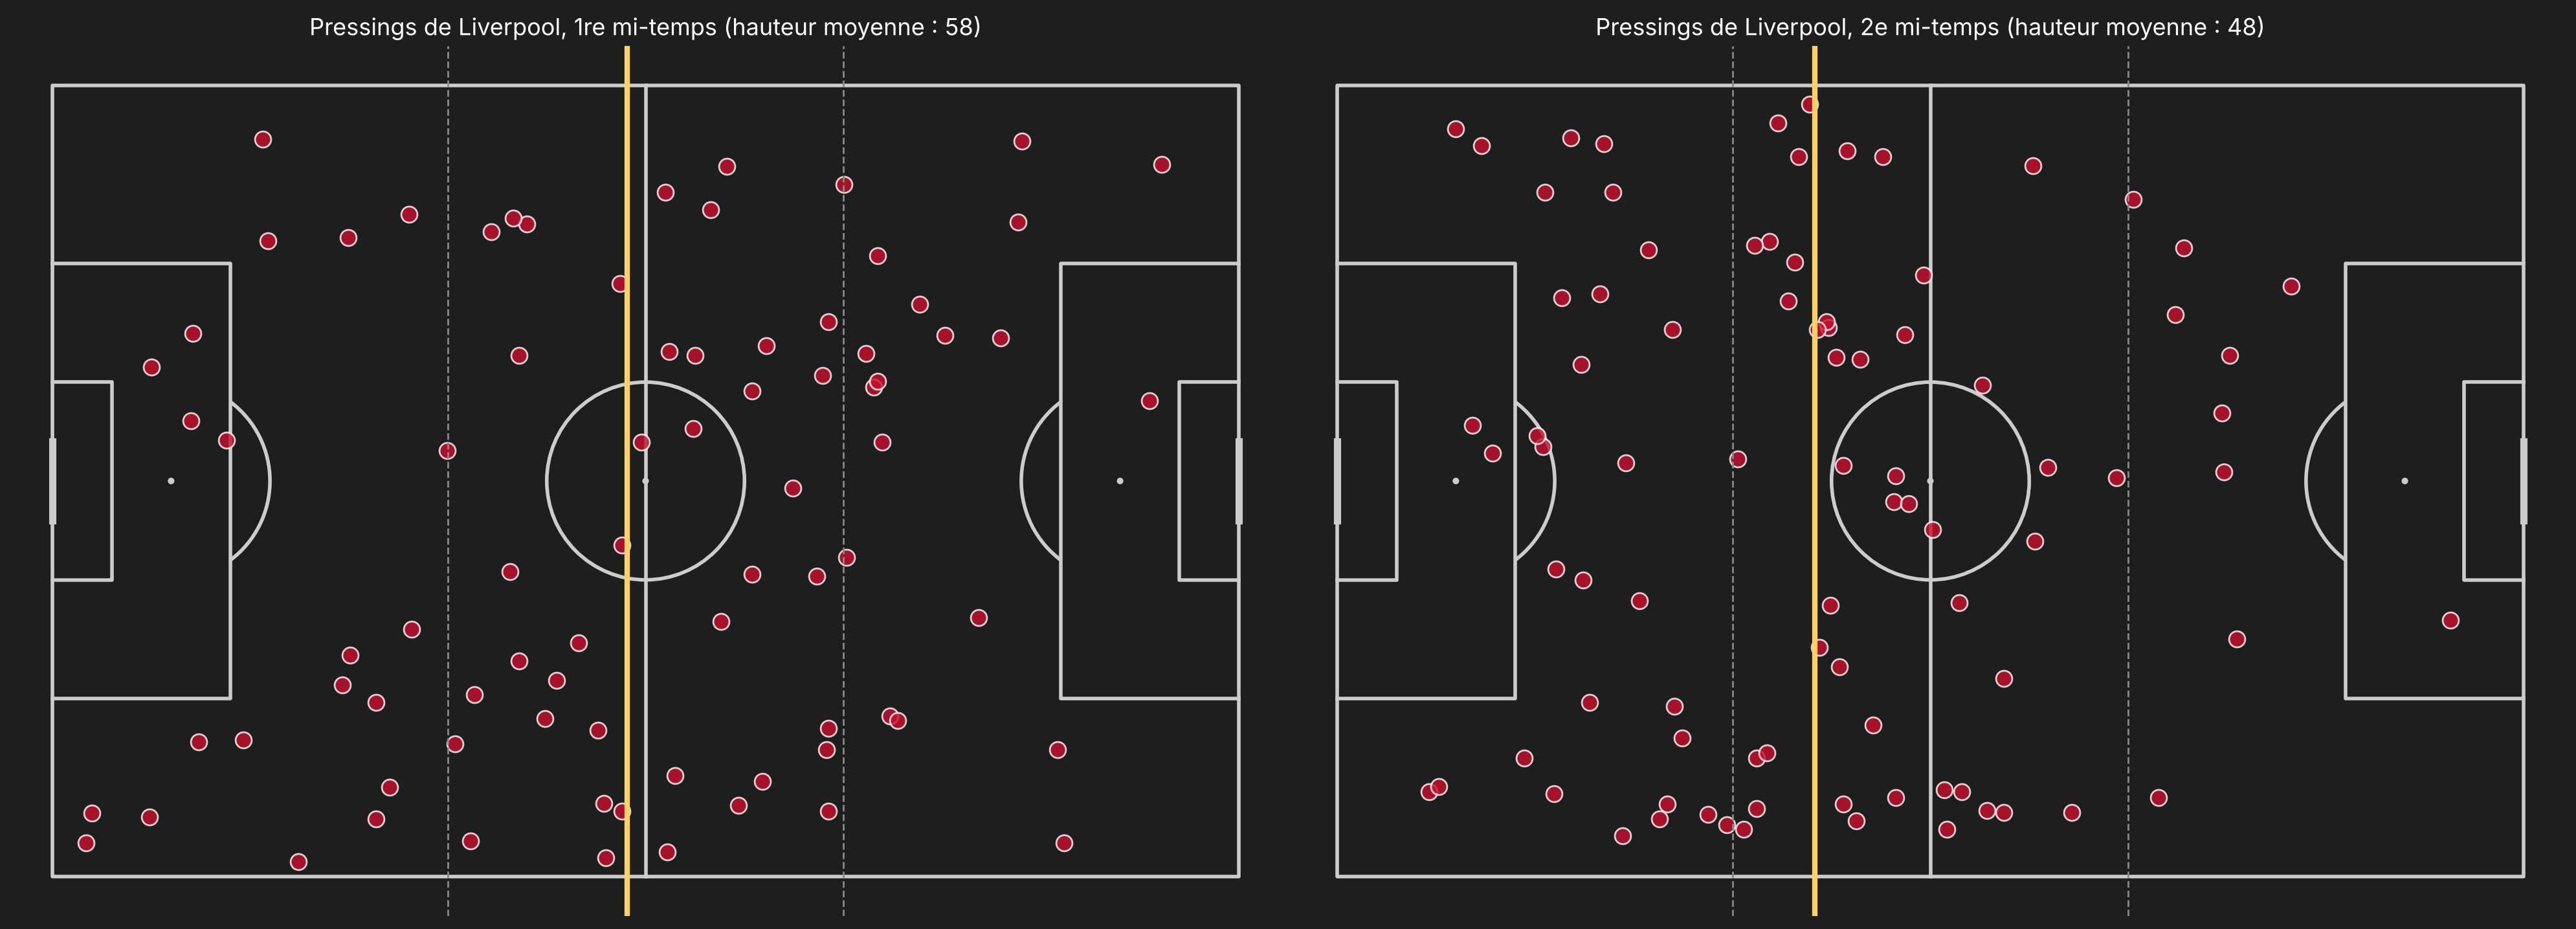

In [28]:
pitch = Pitch(pitch_type="statsbomb", pitch_color="#1e1e1e", line_color="#cccccc")  # terrain StatsBomb
fig, axes = pitch.draw(nrows=1, ncols=2, figsize=(20, 8))                          # deux terrains côte à côte
for ax, periode, titre in [(axes[0], 1, "Pressings de Liverpool, 1re mi-temps"),   # terrain de gauche
                           (axes[1], 2, "Pressings de Liverpool, 2e mi-temps")]:   # terrain de droite
    pr = pressings_liv[pressings_liv["period"] == periode]                         # pressings de la mi-temps
    pitch.scatter(pr["x"], pr["y"], s=80, color="#c8102e",                         # un point rouge par pressing
                  edgecolors="white", alpha=0.8, ax=ax)
    for limite in [40, 80]:                                                        # limites entre les tiers
        ax.axvline(limite, color="#888888", linestyle="--", lw=1)                  # ligne verticale pointillée
    moyenne = pr["x"].mean()                                                       # hauteur moyenne des pressings
    ax.axvline(moyenne, color="#ffd166", lw=3)                                     # ligne jaune = hauteur moyenne
    ax.set_title(f"{titre} (hauteur moyenne : {moyenne:.0f})", color="white", fontsize=13)  # titre avec la moyenne
fig.set_facecolor("#1e1e1e")                                                       # fond assorti
plt.savefig("pressings_liverpool_mt1_mt2.png", dpi=150, bbox_inches="tight")       # sauvegarde
plt.show()                                                                          # affiche

### Les trois buts de Liverpool

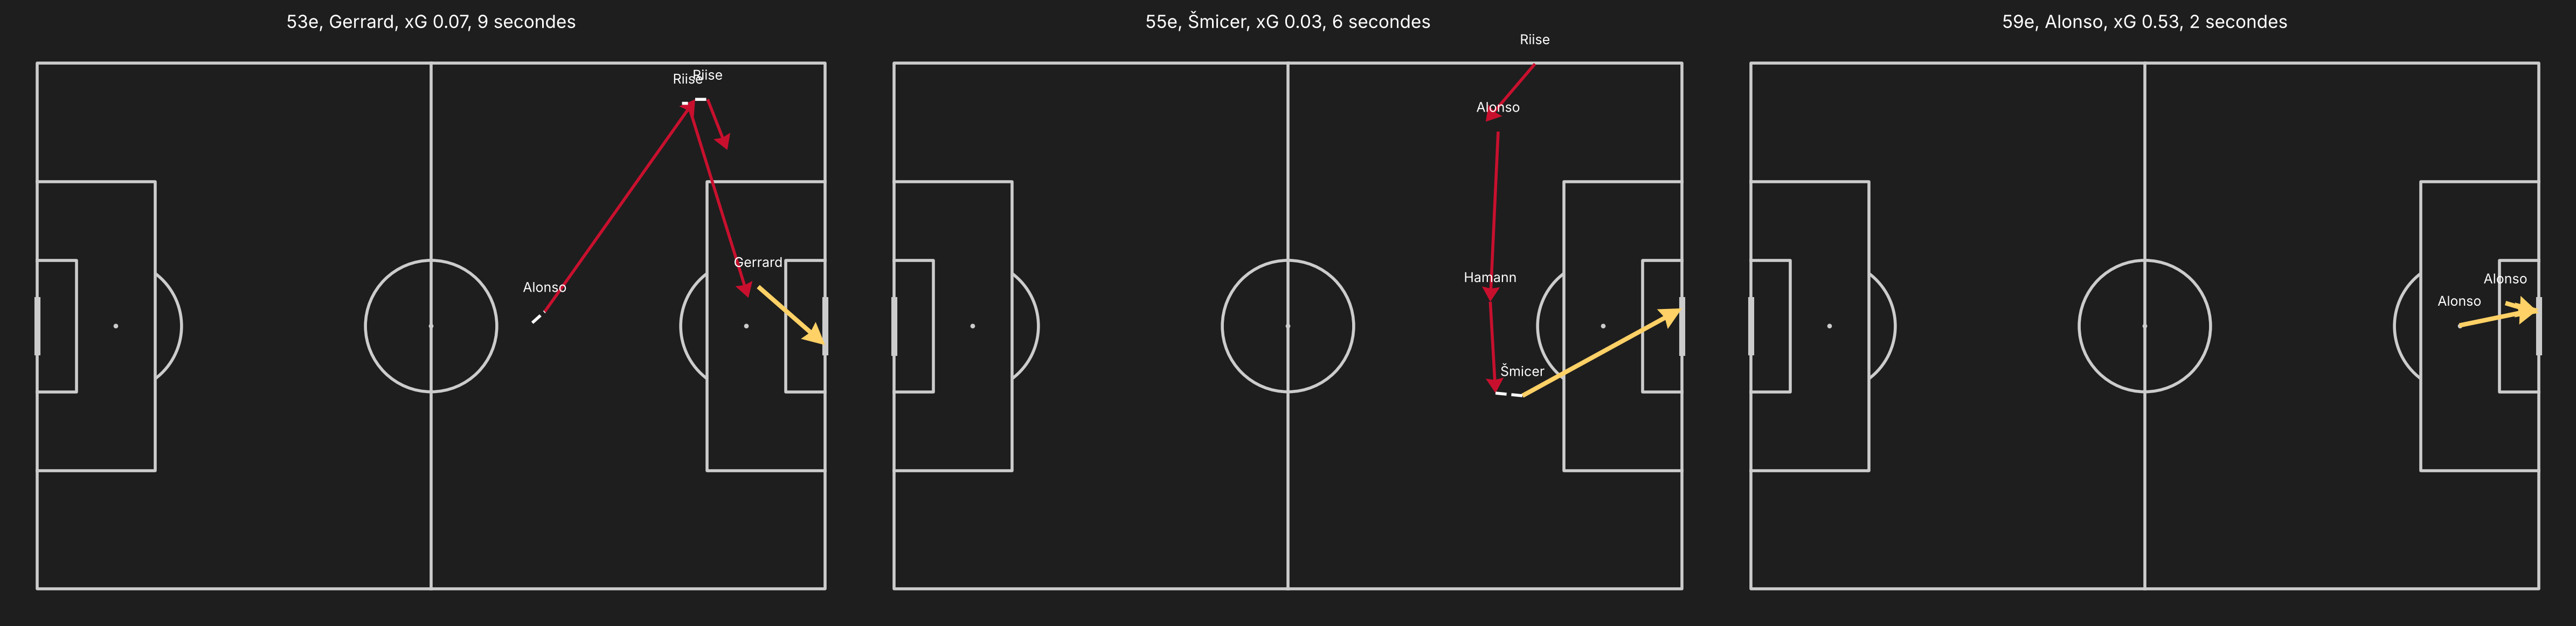

In [29]:
pitch = Pitch(pitch_type="statsbomb", pitch_color="#1e1e1e", line_color="#cccccc")  # terrain StatsBomb
fig, axes = pitch.draw(nrows=1, ncols=3, figsize=(24, 6))                          # trois terrains côte à côte
for ax, (_, tir) in zip(axes, buts_liv.iterrows()):                                # un terrain par but de Liverpool
    dessiner_but(tir, ax, "#c8102e")                                               # construction du but en rouge Liverpool
fig.set_facecolor("#1e1e1e")                                                       # fond assorti
plt.savefig("buts_liverpool_mt2.png", dpi=150, bbox_inches="tight")                # sauvegarde
plt.show()                                                                          # affiche

### Les deux équipes tranche par tranche

Mêmes tranches que dans la partie 3 : nombre de passes et xG créés par chaque équipe.

In [30]:
lignes = []                                                                     # une ligne par tranche
for nom, periode, debut, fin in tranches:                                       # mêmes tranches que la partie 3
    t = df[(df["period"] == periode) & (df["minute"].between(debut, fin))]      # toutes les actions de la tranche
    ligne = {"tranche": nom}                                                    # la ligne commence par le nom de la tranche
    for equipe, court in [("AC Milan", "Milan"), ("Liverpool", "Liverpool")]:   # pour chaque équipe
        e = t[t["team_name"] == equipe]                                         # actions de l'équipe
        ligne[f"passes {court}"] = (e["type_name"] == "Pass").sum()             # nombre de passes
        ligne[f"xG {court}"] = round(e["shot_statsbomb_xg"].sum(), 2)           # total des xG de ses tirs
    lignes.append(ligne)                                                        # on ajoute la ligne
pd.DataFrame(lignes).set_index("tranche")                                       # tableau final

,passes Milan,xG Milan,passes Liverpool,xG Liverpool
tranche,,,,
1re mi-temps,256,1.30,250,0.23
45e à 52e,51,0.09,47,0.01
53e à 60e (les 6 minutes),27,0.00,42,1.43
61e à 75e,64,0.28,68,0.08
76e à 90e,89,0.62,88,0.00


### L'efficacité de Liverpool

Attention : pour le troisième but, le penalty arrêté (0,78 xG) et le rebond (0,53 xG) sont la même occasion, leurs xG ne s'additionnent pas vraiment.

In [31]:
tirs_liv_mt2 = df[(df["type_name"] == "Shot") & (df["team_name"] == "Liverpool")   # tirs de Liverpool
                  & (df["period"] == 2)].copy()                                     # en deuxième mi-temps
tirs_liv_mt2["joueur"] = tirs_liv_mt2["player_name"].map(noms_courts)               # nom court du tireur
print("Tirs de Liverpool en 2e mi-temps :", len(tirs_liv_mt2))                      # nombre total de tirs
print("xG total :", round(tirs_liv_mt2["shot_statsbomb_xg"].sum(), 2))              # somme des xG
print("Buts :", (tirs_liv_mt2["shot_outcome_name"] == "Goal").sum())                # buts marqués
tirs_liv_mt2[tirs_liv_mt2["minute"].between(53, 60)][                               # tirs des six minutes
    ["minute", "joueur", "shot_type_name", "shot_statsbomb_xg", "shot_outcome_name"]].round(2)  # détail

Tirs de Liverpool en 2e mi-temps : 9
xG total : 1.51
Buts : 3


,minute,joueur,shot_type_name,shot_statsbomb_xg,shot_outcome_name
2184,53,Gerrard,Open Play,0.07,Goal
2266,55,Šmicer,Open Play,0.03,Goal
2308,56,Alonso,Open Play,0.02,Blocked
2368,59,Alonso,Penalty,0.78,Saved
2372,59,Alonso,Open Play,0.53,Goal


### Conclusion de la partie 4

Comme chez Milan, un schéma revient sur les buts de Liverpool : Alonso et Riise sont dans les deux premiers buts, et Alonso marque le troisième. Mais la nature des actions est très différente. Les buts de Milan viennent d'actions qui percutent : passes dans l'axe, dribbles, passes en profondeur qui cassent les lignes (0,61 et 0,45 xG). Ceux de Liverpool viennent d'actions qui, à première vue, ne sont pas dangereuses : un centre repris de la tête (0,07 xG), une frappe de loin devant les défenseurs (0,03 xG), puis un penalty arrêté et repris. Liverpool revient donc grâce à un changement de structure qui reprend le contrôle du milieu (42 passes contre 27 pendant les six minutes), à une grande efficacité sur des occasions faibles, et à un Milan qui ne met plus de pression (aucune des 8 dernières actions du but de Gerrard n'est pressée).

## Synthèse générale

En première mi-temps, Milan ne domine pas par la possession mais par la vitesse : le circuit Pirlo, Kaká, Crespo frappe en moins de 10 secondes, profitant d'un Liverpool qui laisse Kaká libre (3 réceptions sous pression sur 26) et perd la guerre du milieu.

À la pause, Benítez change de structure : trois défenseurs centraux, Hamann à côté d'Alonso, Hyypiä au centre du jeu. Liverpool presse plus souvent mais plus bas, et Kaká, toujours libre, ne trouve plus d'espace dans le dos (0 passe en profondeur, contre 4 en première mi-temps).

Entre la 53e et la 60e minute, Milan se déconnecte (27 passes, 59 % de réussite, pressing au plus bas) et Liverpool marque trois fois sur des occasions faibles (0,10 xG pour les deux premiers buts), puis sur un penalty repris.

Ce que ce match apprend à un staff : un avantage tactique (les espaces de Kaká) peut disparaître avec un seul changement de structure, et une équipe qui arrête de presser, même huit minutes, laisse l'adversaire jouer sans gêne.

### Pistes pour aller plus loin

Confirmer en vidéo les hypothèses que les données ne peuvent pas trancher (écart entre les défenseurs centraux sur les buts, mental). Analyser les prolongations, où Milan reprend le contrôle (197 passes contre 116, 0,86 xG contre 0,06) sans marquer, et la séance de tirs au but.